# Day 4 · ResNet18 한 줄씩 이해하기 — 실습 0~8번

**목표:** 이미지가 클래스 점수가 되는 과정과, loss로 가중치를 고치는 과정을 각 코드 줄과 연결해 설명하기.

- 원본: [01_ResNet18_CIFAR10.ipynb](../../vision/01_ResNet18_CIFAR10.ipynb). 원본은 수정하지 않았습니다.
- **시험 범위는 6번까지 유지합니다.** 7~8번은 요청하신 이해용 추가 학습이며 시험 문제로 내지 않습니다. [범위 기록](../../EXAM-SCOPE.md)
- 날짜가 바뀌었지만 이 자료는 Day 4에서 이어진 요청입니다. 저장일: 2026-11-06.
- 회색 코드 상자의 **원본 코드**는 읽기용 Markdown입니다. 자동 설치·CIFAR 다운로드·20 epoch 학습·체크포인트 저장을 실행하지 않습니다.
- ▶로 실행할 수 있는 **작은 실험 코드 셀**은 합성 데이터로 동작합니다. 실제 CIFAR 정확도를 측정하는 실험은 아닙니다. 위에서 아래로 실행하세요.
- 실험에 필요한 패키지: torch, torchvision, matplotlib, numpy, Pillow. 기존 `env_aias_test` 커널을 선택하세요. 자동 설치 코드는 실행하지 않습니다.
- 한 번에 모두 외우지 마세요. **한 소단락 읽기 → 작은 실험 → 말로 답하기 → 해설 확인** 순서로 진행하세요. 막히면 원본 셀 번호·줄 번호를 알려 주세요.

## 목차

0. [환경 준비](#section-0)
1. [Dataset·전처리·배치·이미지 표시](#section-1)
2. [CIFAR용 ResNet18·잔차 연결·파라미터](#section-2)
3. [학습 유틸리티·optimizer·AMP·평가](#section-3)
4. [epoch 반복·체크포인트·학습률](#section-4)
5. [추론·확률·예측 번호](#section-5)
6. [혼동행렬·클래스별 정확도·오분류](#section-6)
7. [추가 이해: Activation Map](#section-7)
8. [추가 이해: Convolution Kernel](#section-8)

## 먼저 알아둘 이름과 shape

원본의 별명은 아래 import에서 정해집니다. `tfms`, `model`, `criterion`은 패키지 이름이 아니라 변수입니다.

```python
import torch
import torch.nn as nn                  # nn.Conv2d = torch.nn.Conv2d
import torch.nn.functional as F       # F.softmax = torch.nn.functional.softmax
import torchvision
import torchvision.transforms as T    # T.Compose = torchvision.transforms.Compose
import torchvision.models as models   # models.resnet18 = torchvision.models.resnet18
from torch.utils.data import DataLoader
import numpy as np                    # np.arange = numpy.arange
import matplotlib.pyplot as plt       # plt.imshow = matplotlib.pyplot.imshow
```

이 문서의 **실제 PyTorch shape는 B,C,H,W**(배치·채널·높이·너비)입니다. 강의의 B,C,W,H 표기는 정사각형에서 숫자가 같지만, API의 축 순서는 BCHW입니다.

```text
이미지 B장 (B,3,32,32)
  → Conv·BN·ReLU (B,64,32,32)
  → layer1 (B,64,32,32)
  → layer2 (B,128,16,16)
  → layer3 (B,256,8,8)
  → layer4 (B,512,4,4)
  → 평균 풀링 (B,512,1,1) → flatten (B,512)
  → FC (B,10) = logits
                         labels (B,) = 정답
                 두 값을 criterion에 넣음
                           ↓
                       loss ()
                           ↓ backward: 각 파라미터의 gradient 계산
                           ↓ optimizer.step: 가중치 수정
                       다음 배치
```

<a id="section-0"></a>
# 0) 환경 준비

환경 코드는 도구를 준비하는 부분입니다. 설치·다운로드 절차는 시험 출제에서 제외합니다. `import`는 라이브러리를 가져오고 `as`는 별명을 붙입니다. 예: `import torch.nn as nn` 다음 `nn.Linear`와 `torch.nn.Linear`는 같은 클래스입니다.

seed는 난수의 시작점을 고정합니다. 다만 원본은 `deterministic=False`, `benchmark=True`라 완전한 재현성을 보장하는 설정은 아닙니다. GPU가 없으면 CPU로 동작합니다. ONNX 설치 부분은 원본 환경 코드라 보존했지만, ONNX 실습 자체는 이 자료 범위가 아닙니다.

## 원본 전체 셀 3 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 3 · L1~L10

```python
import importlib.util
import subprocess
import sys

def ensure_package(pkg_name: str, import_name=None):
    """
    패키지 설치 여부를 확인하고, 설치되어 있지 않으면 설치합니다.
    """
    name = import_name or pkg_name
    # 패키지가 설치되어 있는지 확인
```

**L1.** 모듈 존재 확인을 가져옵니다.

**L2.** 별도 명령 실행을 가져옵니다.

**L3.** 현재 Python 실행 파일 경로을 가져옵니다.

**L5.** `ensure_package` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L6.** 함수 설명 문자열(docstring)의 시작 또는 끝입니다. 계산 명령이 아닙니다.

**L7.** 함수의 목적을 설명하는 docstring 본문입니다. 설치 여부를 확인한 뒤 필요하면 설치합니다.

**L8.** 함수 설명 문자열(docstring)의 시작 또는 끝입니다. 계산 명령이 아닙니다.

**L9.** import_name이 있으면 그것을, None이나 빈 문자열이면 pkg_name을 선택합니다. pip 설치 이름과 import 이름이 다를 수 있어 구분합니다.

**L10.** 실행되지 않는 주석입니다. 패키지가 설치되어 있는지 확인

### 셀 3 · L11~L20

```python
    if importlib.util.find_spec(name) is None:
        print(f"[install] {pkg_name} 라이브러리를 설치 중입니다... (import name: {name})")
        try:
            # -q 옵션을 추가하여 설치 과정을 간결하게 유지할 수 있습니다.
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])
            print(f"[success] {pkg_name} 설치 완료.")
        except subprocess.CalledProcessError as e:
            print(f"[error] {pkg_name} 설치 실패: {e}")
    else:
        print(f"[ok] {pkg_name} 이미 설치되어 있습니다.")
```

**L11.** 모듈을 찾을 수 있는지 확인합니다. None이면 설치가 필요한 것으로 판단합니다. 실제 import 성공까지 보장하는 검사는 아닙니다.

**L12.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L13.** 실패할 수 있는 코드를 실행하고, 예외가 발생하면 아래 except에서 처리합니다.

**L14.** 실행되지 않는 주석입니다. -q 옵션을 추가하여 설치 과정을 간결하게 유지할 수 있습니다.

**L15.** 현재 커널의 Python(sys.executable)로 pip install을 실행합니다. -m은 모듈 실행, -q는 출력 축소입니다. 실패하면 예외가 나며 아래 except가 받습니다.

**L16.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L17.** 지정한 예외가 발생하면 e에 받아 오류 메시지를 출력합니다. 모든 실패를 성공으로 바꾸는 것은 아닙니다.

**L18.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L19.** 바로 앞 if 조건이 거짓일 때 이 분기의 들여쓴 코드를 실행합니다.

**L20.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

### 셀 3 · L21~L30

```python

# 설치가 필요한 패키지 리스트 (패키지명, 임포트명)
# 임포트명이 패키지명과 다른 경우 튜플로 지정합니다.
packages = [
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("matplotlib", "matplotlib"),
    ("onnx", "onnx"),
]

```

**L22.** 실행되지 않는 주석입니다. 설치가 필요한 패키지 리스트 (패키지명, 임포트명)

**L23.** 실행되지 않는 주석입니다. 임포트명이 패키지명과 다른 경우 튜플로 지정합니다.

**L24.** 뒤에서 사용할 항목을 담는 리스트를 만듭니다. 빈 리스트에는 반복문에서 append로 항목을 추가합니다.

**L25.** 설치할 패키지 이름과 import할 이름을 튜플 한 쌍으로 지정합니다. 바깥 리스트의 항목입니다.

**L26.** 설치할 패키지 이름과 import할 이름을 튜플 한 쌍으로 지정합니다. 바깥 리스트의 항목입니다.

**L27.** 설치할 패키지 이름과 import할 이름을 튜플 한 쌍으로 지정합니다. 바깥 리스트의 항목입니다.

**L28.** 설치할 패키지 이름과 import할 이름을 튜플 한 쌍으로 지정합니다. 바깥 리스트의 항목입니다.

**L29.** 앞에서 시작한 리스트·함수 호출·딕셔너리를 닫습니다. 이 줄 자체에 별도 계산은 없습니다.

### 셀 3 · L31~L33

```python
# 루프를 돌며 확인 및 설치
for pkg, imp in packages:
    ensure_package(pkg, imp)
```

**L31.** 실행되지 않는 주석입니다. 루프를 돌며 확인 및 설치

**L32.** 리스트나 텐서에서 항목을 하나씩 꺼내 들여쓴 본문을 반복합니다. 변수 두 개면 항목의 두 값을 나누어 받습니다.

**L33.** 패키지 이름과 import 이름으로 앞의 설치 확인 함수를 호출합니다. 이 안내서에서는 읽기용입니다.

## 원본 전체 셀 4 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 4 · L1~L10

```python
import os  # path/환경 확인
import random  # seed 고정
import time  # epoch 시간 측정
import numpy as np  # 수치 계산
import torch  # PyTorch 본체
import torch.nn as nn  # 모델 레이어
import torch.nn.functional as F  # softmax 등 함수
from torch.utils.data import DataLoader  # 데이터 로더
import torchvision  # vision dataset/util
import torchvision.transforms as T  # transform
```

**L1.** 파일 경로·CPU 개수 같은 운영체제 기능을 가져옵니다.

**L2.** Python 난수을 가져옵니다.

**L3.** 시간 측정을 가져옵니다.

**L4.** 배열·수치 계산을 가져옵니다. `as np`는 이 모듈에 붙이는 별명입니다.

**L5.** 텐서·자동 미분·모델 학습을 가져옵니다.

**L6.** Conv·Linear·손실함수 같은 레이어을 가져옵니다. `as nn`는 이 모듈에 붙이는 별명입니다.

**L7.** softmax 같은 함수형 연산을 가져옵니다. `as F`는 이 모듈에 붙이는 별명입니다.

**L8.** torch.utils.data 안의 DataLoader를 직접 가져와 긴 소속 이름 없이 사용합니다.

**L9.** 이미지 Dataset·격자 이미지 도구을 가져옵니다.

**L10.** 이미지 전처리을 가져옵니다. `as T`는 이 모듈에 붙이는 별명입니다.

### 셀 4 · L11~L20

```python
import torchvision.models as models  # resnet18
import matplotlib.pyplot as plt  # 시각화

print('torch:', torch.__version__)  # torch 버전 출력
print('torchvision:', torchvision.__version__)  # torchvision 버전 출력
print('cuda available:', torch.cuda.is_available())  # GPU 사용 가능 여부
if torch.cuda.is_available():
    print('gpu:', torch.cuda.get_device_name(0))  # GPU 이름 출력

try:
```

**L11.** ResNet 같은 모델을 가져옵니다. `as models`는 이 모듈에 붙이는 별명입니다.

**L12.** 그래프·이미지 표시을 가져옵니다. `as plt`는 이 모듈에 붙이는 별명입니다.

**L14.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L15.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L16.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L17.** CUDA GPU를 사용할 수 있을 때만 들여쓴 코드를 실행합니다.

**L18.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L20.** 실패할 수 있는 코드를 실행하고, 예외가 발생하면 아래 except에서 처리합니다.

### 셀 4 · L21~L30

```python
    get_ipython().system('nvidia-smi -L')  # GPU 목록 확인(가능한 경우)
except Exception as e:
    print('nvidia-smi not available:', e)  # nvidia-smi가 없는 환경이면 무시

def seed_everything(seed: int = 42):
    random.seed(seed)  # python random seed
    np.random.seed(seed)  # numpy seed
    torch.manual_seed(seed)  # torch CPU seed
    torch.cuda.manual_seed_all(seed)  # torch GPU seed
    torch.backends.cudnn.deterministic = False  # 성능 우선(완전 재현성 X)
```

**L21.** Jupyter에서 운영체제 명령 nvidia-smi -L을 호출해 NVIDIA GPU 목록을 확인합니다. Python 계산 코드가 아닙니다.

**L22.** 지정한 예외가 발생하면 e에 받아 오류 메시지를 출력합니다. 모든 실패를 성공으로 바꾸는 것은 아닙니다.

**L23.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L25.** `seed_everything` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L26.** 난수 생성기의 시작점을 seed로 고정합니다. 같은 난수 흐름을 재현하기 위한 설정이며 모든 GPU 연산의 완전 재현성을 보장하지는 않습니다.

**L27.** 난수 생성기의 시작점을 seed로 고정합니다. 같은 난수 흐름을 재현하기 위한 설정이며 모든 GPU 연산의 완전 재현성을 보장하지는 않습니다.

**L28.** PyTorch 난수 시작점을 고정합니다. 예: 초기 가중치와 무작위 텐서를 재현하는 데 사용합니다.

**L29.** CUDA 장치들의 난수 시작점을 설정합니다. CPU 대신 GPU의 난수 흐름을 위한 설정입니다.

**L30.** False이므로 결정적 알고리즘만 강제하지 않습니다. 속도 위주이며 완전 재현성 설정은 아닙니다.

### 셀 4 · L31~L35

```python
    torch.backends.cudnn.benchmark = True  # 입력 크기 고정이면 속도 향상

seed_everything(42)  # seed 고정(실험 재현성)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # 실행 디바이스 선택
device  # 디바이스 출력
```

**L31.** True이면 입력 크기에 맞는 빠른 cuDNN 알고리즘을 탐색합니다. 입력 크기가 고정된 상황에 유용합니다.

**L33.** 위에서 정의한 seed 설정 함수를42라는 값으로 호출합니다.

**L34.** CUDA를 쓸 수 있으면 cuda, 아니면 cpu를 선택합니다. 이후 모델·입력·정답을 같은 device에 둡니다.

**L35.** Jupyter 셀 마지막 표현식으로 선택된 장치 객체를 표시합니다.

## 0번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

In [1]:
import torch
import torchvision
import matplotlib.pyplot
torch.manual_seed(42)
torch.set_num_threads(2)
print('torch:', torch.__version__, 'torchvision:', torchvision.__version__)
print('작은 예제의 장치: CPU (GPU가 없어도 실행 가능)')
print('Linear(3,2) 파라미터 수:', sum(p.numel() for p in torch.nn.Linear(3,2).parameters()))

torch: 2.5.1 torchvision: 0.20.1+cpu
작은 예제의 장치: CPU (GPU가 없어도 실행 가능)
Linear(3,2) 파라미터 수: 8


### 잠깐 가리고 설명하기

GPU가 없으면 device는 무엇인가요? T는 어느 패키지의 별명인가요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

cpu입니다. T는 torchvision.transforms입니다.

</details>

<a id="section-1"></a>
# 1) Dataset·전처리·배치

Dataset은 한 장과 정답을 꺼내고, DataLoader는 여러 장을 묶습니다. 예: 한 샘플 `(3,32,32)`와 정답 `3` → 네 장 배치 `(4,3,32,32)`와 labels `(4,)`.

```text
PIL RGB 32×32 → padding 4: 40×40 → RandomCrop: 32×32 → 좌우 반전 가능
  → ToTensor: (3,32,32), 0~1 → Normalize: 같은 shape, 값만 조정
  → DataLoader: (B,3,32,32)
```

test는 Crop·Flip 없이 같은 mean/std로 정규화합니다. Normalize는 `(x-mean)/std`이며 정규분포나 고정된 -2.5~2.5 범위를 보장하지 않습니다. `denorm`은 `x*std+mean`으로 역변환합니다. 원본 denorm은 CPU 배치 입력을 가정하므로 GPU 이미지는 `.cpu()` 후 넣습니다.

## 원본 전체 셀 6 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 6 · L1~L10

```python
# CIFAR-10에서 널리 쓰는 normalize 값
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)  # 채널별 평균(R,G,B)
CIFAR10_STD  = (0.2023, 0.1994, 0.2010)  # 채널별 표준편차(R,G,B)

train_tfms = T.Compose([  # train transform(augmentation 포함)
    T.RandomCrop(32, padding=4),  # 32x32를 padding 후 random crop
    T.RandomHorizontalFlip(),  # 좌우 반전
    T.ToTensor(),  # PIL -> torch tensor (C,H,W), 0~1
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),  # 정규화, -2.5~2.5
])
```

**L1.** 실행되지 않는 주석입니다. CIFAR-10에서 널리 쓰는 normalize 값

**L2.** RGB 순서의 고정 평균 3개입니다. 각 채널에서 뺄 기준이며 이미지마다 새로 계산하지 않습니다.

**L3.** RGB 순서의 고정 표준편차 3개입니다. Normalize에서 채널별로 나눌 기준입니다.

**L5.** 여러 전처리를 리스트의 위→아래 순서로 적용할 객체를 만듭니다. 정의 시점에는 아직 이미지가 들어오지 않았습니다.

**L6.** 32×32를 상하좌우 4씩 패딩해 40×40으로 만든 다음 임의 위치의 32×32를 잘라냅니다. 최종 이미지 크기는 유지합니다.

**L7.** 기본 확률 0.5로 좌우 반전합니다. 학습 이미지를 다양하게 보여주는 augmentation(증강)입니다.

**L8.** 이 실습의 uint8 PIL 이미지를 (C,H,W) 실수 텐서로 바꾸고 0~255를 0~1로 조절합니다.

**L9.** 채널별 (x-mean)/std를 적용합니다. shape는 같고, 출력 범위가 정확히 -2.5~2.5로 고정되거나 정규분포가 되는 것은 아닙니다.

**L10.** 앞에서 시작한 리스트·함수 호출·딕셔너리를 닫습니다. 이 줄 자체에 별도 계산은 없습니다.

### 셀 6 · L11~L20

```python

test_tfms = T.Compose([  # test transform(augmentation 없음)
    T.ToTensor(),  # 텐서 변환
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD),  # 정규화
])

data_root = './data'  # 데이터 저장 경로
train_set = torchvision.datasets.CIFAR10(root=data_root, train=True, download=True, transform=train_tfms)  # train set
test_set  = torchvision.datasets.CIFAR10(root=data_root, train=False, download=True, transform=test_tfms)  # test set

```

**L12.** 여러 전처리를 리스트의 위→아래 순서로 적용할 객체를 만듭니다. 정의 시점에는 아직 이미지가 들어오지 않았습니다.

**L13.** 이 실습의 uint8 PIL 이미지를 (C,H,W) 실수 텐서로 바꾸고 0~255를 0~1로 조절합니다.

**L14.** 채널별 (x-mean)/std를 적용합니다. shape는 같고, 출력 범위가 정확히 -2.5~2.5로 고정되거나 정규분포가 되는 것은 아닙니다.

**L15.** 앞에서 시작한 리스트·함수 호출·딕셔너리를 닫습니다. 이 줄 자체에 별도 계산은 없습니다.

**L17.** 데이터 폴더의 상대 경로를 지정합니다. 현재 Jupyter 작업 폴더 기준입니다.

**L18.** CIFAR10 Dataset을 만듭니다. train=True는 학습 분할, False는 시험 분할입니다. transform은 샘플을 꺼낼 때 적용됩니다. download=True는 필요 시 다운로드하며 시험 출제 제외입니다.

**L19.** CIFAR10 Dataset을 만듭니다. train=True는 학습 분할, False는 시험 분할입니다. transform은 샘플을 꺼낼 때 적용됩니다. download=True는 필요 시 다운로드하며 시험 출제 제외입니다.

### 셀 6 · L21~L30

```python
class_names = train_set.classes  # 클래스 이름 목록
num_classes = len(class_names)  # 클래스 개수(10)
print('classes:', class_names)  # 클래스 출력

# 이미지 사이즈 출력
x0, y0 = train_set[0]  # 한 샘플 로드(이미 transform 적용된 텐서)
print('Sample image tensor shape (C,H,W):', tuple(x0.shape))  # (3,32,32)

batch_size = 256  # 배치 크기
num_workers = min(8, os.cpu_count() or 2)  # dataloader worker 수(환경에 맞게)
```

**L21.** Dataset의 클래스 이름 목록을 꺼냅니다. 리스트의 인덱스가 정답 클래스 번호와 대응합니다.

**L22.** 클래스 이름 목록 길이입니다. CIFAR10은 10이며 RGB 채널 수 3과 다른 개념입니다.

**L23.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L25.** 실행되지 않는 주석입니다. 이미지 사이즈 출력

**L26.** 첫 샘플을 꺼내 이미지와 정답으로 나눠 받습니다. x0=(3,32,32), y0는 정수 하나입니다. [0]은 클래스가 아니라 샘플 위치입니다.

**L27.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L29.** 한 번에 처리할 최대 이미지 수를256으로 설정합니다. 전체 데이터 수와 다릅니다.

**L30.** CPU 개수와 8 중 작은 수를 loader 작업자 수로 씁니다. cpu_count가 None이면 2를 씁니다. 환경 문제를 피하는 작은 예제에서는 0으로 둡니다.

### 셀 6 · L31~L35

```python

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=True)  # train loader
test_loader  = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=True)  # test loader

print('Total batch size (train: %d, test: %d)' % (len(train_loader), len(test_loader)))  # 배치 개수 확인
```

**L32.** Dataset을 배치로 묶는 로더를 만듭니다. shuffle은 순서 섞기, num_workers는 작업자 수, pin_memory는 GPU 전송에 유용한 CPU 메모리 설정입니다. 기본 drop_last=False라 마지막 배치가 작을 수 있습니다.

**L33.** Dataset을 배치로 묶는 로더를 만듭니다. shuffle은 순서 섞기, num_workers는 작업자 수, pin_memory는 GPU 전송에 유용한 CPU 메모리 설정입니다. 기본 drop_last=False라 마지막 배치가 작을 수 있습니다.

**L35.** 출력 문구는 batch size라고 되어 있지만 len(loader)는 배치 개수입니다. 50,000장/256이면 마지막80장을 포함해196배치입니다.

## 원본 전체 셀 7 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 7 · L1~L10

```python

def denorm(x): # -2.5~2.5
    mean = torch.tensor(CIFAR10_MEAN).view(1,3,1,1)  # (1,3,1,1) 형태로 broadcast
    std  = torch.tensor(CIFAR10_STD).view(1,3,1,1)  # (1,3,1,1) 형태로 broadcast
    return x * std + mean  # 정규화 역변환, 0~1

images, labels = next(iter(train_loader))  # 한 배치 가져오기
images_dn = denorm(images[:16]).clamp(0,1)  # 앞 16장만 역정규화 후 [0,1]로 clip

grid = torchvision.utils.make_grid(images_dn, nrow=8)  # 그리드로 묶기(C,H,W)
```

**L2.** `denorm` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L3.** RGB 평균을 (3,)에서 (1,3,1,1)로 바꿉니다. B,H,W 방향으로 같은 채널 값을 broadcasting하기 위한 모양입니다.

**L4.** RGB 표준편차를 (1,3,1,1)로 바꿉니다. 원본은 CPU 텐서이므로 denorm에 CPU 배치를 넣습니다.

**L5.** Normalize의 역연산입니다. 예: (0.6-0.5)/0.2=0.5로 정규화했으면 0.5*0.2+0.5=0.6으로 돌아갑니다.

**L7.** iter는 로더의 반복자를 만들고 next는 첫 배치 하나를 꺼냅니다. images=(B,3,32,32), labels=(B,)입니다.

**L8.** 정규화를 역변환한 후 clamp(0,1)로 표시 범위를 제한합니다. 앞의 슬라이스나 인덱싱으로 표시할 이미지만 선택합니다. shape는 선택한 이미지 수에 맞습니다.

**L10.** 여러 이미지를 한 장의 격자 이미지로 묶습니다. nrow=8은 한 줄에 최대 8장입니다. 출력은 CHW이며 padding 때문에 단순 32의 배수보다 커질 수 있습니다.

### 셀 7 · L11~L17

```python
plt.figure(figsize=(12,4))
plt.imshow(grid.permute(1,2,0))  # CHW -> HWC 로 변환 후 표시
plt.axis('off')
plt.title('CIFAR-10 samples (denormalized)')
plt.show()

print('labels:', [class_names[int(x)] for x in labels[:16]])  # 라벨 이름 출력
```

**L11.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L12.** 채널 우선 CHW를 그림 표시용 HWC로 축 순서만 바꿉니다. 예: (3,32,32)→(32,32,3).

**L13.** off이면 이미지 주변 좌표축을 감춥니다. 데이터 값은 바뀌지 않습니다.

**L14.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L15.** 준비한 그림을 화면에 표시합니다.

**L17.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

## 1번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

In [2]:
import torch
import torchvision
import numpy
from PIL import Image

# 다운로드 없이 만든 합성 이미지입니다. CIFAR 사진이 아닙니다.
demo_pil = Image.fromarray(numpy.full((32,32,3), 153, dtype=numpy.uint8))
demo_transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.5,0.5,0.5), (0.2,0.2,0.2)),
])
demo_image = demo_transform(demo_pil)
print('한 장 shape / 한 픽셀:', tuple(demo_image.shape), demo_image[0,0,0].item())
demo_images = torch.stack([demo_image]*5)
demo_labels = torch.tensor([0,1,2,3,4])
demo_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(demo_images,demo_labels),
    batch_size=4, shuffle=False, num_workers=0,
)
for demo_x, demo_y in demo_loader:
    print('배치:', tuple(demo_x.shape), tuple(demo_y.shape))
demo_restored = demo_images * torch.tensor([0.2]*3).view(1,3,1,1) + torch.tensor([0.5]*3).view(1,3,1,1)
print('역정규화한 픽셀:', demo_restored[0,0,0,0].item())
assert torch.allclose(demo_restored, torch.full_like(demo_restored,0.6))

한 장 shape / 한 픽셀: (3, 32, 32) 0.5000001192092896
배치: (4, 3, 32, 32) (4,)
배치: (1, 3, 32, 32) (1,)
역정규화한 픽셀: 0.6000000238418579


### 잠깐 가리고 설명하기

이미지5장을 batch_size=4로 묶고 drop_last=False이면 두 배치 shape는?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

(4,3,32,32), (1,3,32,32)입니다. labels는(4,), (1,)입니다.

</details>

<a id="section-2"></a>
# 2) CIFAR용 ResNet18 모델 준비

원래 ImageNet용 ResNet18은 7×7 stride 2 첫 Conv와 MaxPool, 1000개 출력입니다. 실습은 첫 Conv를 3×3 stride 1 padding 1, MaxPool을 Identity, FC를 10개 출력으로 바꿉니다. **출력 채널 수는 커널 크기가 아니라 out_channels가 결정합니다.**

```text
원본 이미지 1장: 높이32 × 너비32 × RGB3
               ↓ 텐서·정규화·배치
          (1,3,32,32)
               ↓ 첫 Conv: 3→64, k3,s1,p1
          (1,64,32,32)
               ↓ BN → ReLU → Identity
          x=(1,64,32,32)  ← 첫 잔차 블록 입력
               ├──────────────────────┐
               ↓                      │
         Conv 64→64                   │
               ↓ BN → ReLU            │ x 그대로 우회
         Conv 64→64                   │
               ↓ BN                  │
       F(x)=(1,64,32,32)               │
               └──────── (+) ◀────────┘
                          ↓ F(x)+x
                    (1,64,32,32)
                          ↓ ReLU
                    (1,64,32,32)
```

여기서 x는 원본 3채널 이미지가 아닙니다. 덧셈은 같은 위치끼리 하므로 128채널이 되지 않습니다. 예: x=2, F(x)=-0.5인 위치는 ReLU(1.5)=1.5. layer2~4의 첫 블록은 채널·공간 크기가 달라져 우회 경로도 1×1 Conv·BN으로 맞춥니다.

BN은 채널마다 B,H,W 방향으로 통계를 구하고 학습 가능한 γ·β를 적용합니다. ReLU는 max(0,x). 둘 다 shape는 유지합니다. 파라미터 수는 숫자 원소 개수입니다. Linear(3,2)는 weight 6개+bias 2개=8개입니다.

## 원본 전체 셀 9 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 9 · L1~L10

```python
def build_resnet18_for_cifar10(num_classes: int = 10):
    model = models.resnet18(weights=None)  # ImageNet pretrained 없이 ResNet18 생성 (from scratch)
    print("\n" + "="*40)
    print("=== PyTorch model structure (Before) ===")  # 모델 구조 출력
    print("="*40 + "\n")
    print(model)  # 구조 출력

    model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)  # CIFAR용 stem
    model.maxpool = nn.Identity()  # maxpool 제거
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # 최종 분류기 출력=10
```

**L1.** `build_resnet18_for_cifar10` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L2.** torchvision.models.resnet18로 기본 ResNet18을 만듭니다. weights=None은 사전학습 가중치를 다운로드하지 않고 새로 초기화한다는 뜻입니다.

**L3.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L4.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L5.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L6.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L8.** 첫 Conv를 입력3→출력64, k=3,s=1,p=1로 교체합니다. (B,3,32,32)→(B,64,32,32). bias=False라 별도 bias 파라미터는 없습니다.

**L9.** Identity는 입력을 그대로 반환합니다. 작은 CIFAR 이미지가 첫 부분에서 과하게 줄어들지 않도록 MaxPool을 대체합니다.

**L10.** 마지막 Linear를 특징512→num_classes로 교체합니다. (B,512)→(B,10). in_features에서 기존 입력 특징 수를 읽습니다.

### 셀 9 · L11~L20

```python
    return model

model = build_resnet18_for_cifar10(num_classes).to(device)  # 모델 생성 후 device 이동

print("\n" + "="*40)
print("=== PyTorch model structure (After) ===")  # 모델 구조 출력
print("="*40 + "\n")
print(model)  # 구조 출력

num_params = sum(p.numel() for p in model.parameters())  # 파라미터 개수
```

**L11.** 수정한 ResNet 모델 객체를 호출한 곳으로 돌려줍니다.

**L13.** 함수를 호출해 CIFAR 수정 모델을 만들고 파라미터와 버퍼를 device로 이동합니다. forward 실행은 아직 아닙니다.

**L15.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L16.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L17.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L18.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L20.** 각 Parameter 텐서의 원소 개수 numel을 sum으로 더합니다. 값의 합이 아니라 개수입니다. 동결 파라미터도 포함하며 BN running_mean 같은 버퍼는 제외합니다.

### 셀 9 · L21~L21

```python
print(f'params: {num_params:,}')  # 출력
```

**L21.** f-string으로 파라미터 개수를 출력합니다. :,는 천 단위 쉼표이므로1234567→1,234,567입니다.

## 2번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

In [3]:
import torch
import torchvision

# 임의 초기화 모델: 다운로드·체크포인트 로딩 없이 shape만 관찰합니다.
demo_resnet = torchvision.models.resnet18(weights=None)
demo_resnet.conv1 = torch.nn.Conv2d(3,64,3,stride=1,padding=1,bias=False)
demo_resnet.maxpool = torch.nn.Identity()
demo_resnet.fc = torch.nn.Linear(demo_resnet.fc.in_features,10)
demo_resnet.eval()
demo_input = torch.randn(1,3,32,32)
with torch.no_grad():
    demo_x = demo_input
    print('입력',tuple(demo_x.shape))
    for demo_name in ['conv1','bn1','relu','maxpool','layer1','layer2','layer3','layer4','avgpool']:
        demo_x = getattr(demo_resnet,demo_name)(demo_x)
        print(demo_name,tuple(demo_x.shape))
    demo_x = torch.flatten(demo_x,1)
    print('flatten',tuple(demo_x.shape))
    demo_scores = demo_resnet.fc(demo_x)
    print('fc',tuple(demo_scores.shape))
assert demo_scores.shape == (1,10)
print('params:',format(sum(p.numel() for p in demo_resnet.parameters()),','))

입력 (1, 3, 32, 32)


conv1 (1, 64, 32, 32)
bn1 (1, 64, 32, 32)
relu (1, 64, 32, 32)
maxpool (1, 64, 32, 32)


layer1 (1, 64, 32, 32)
layer2 (1, 128, 16, 16)
layer3 (1, 256, 8, 8)
layer4 (1, 512, 4, 4)
avgpool (1, 512, 1, 1)
flatten (1, 512)
fc (1, 10)
params: 11,173,962


### 잠깐 가리고 설명하기

첫 잔차 블록의 x는 원본3채널 이미지인가요? F(x)+x의 채널은128인가요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

x는 stem을 지난64채널 특징입니다. 같은 위치끼리 더하므로64채널을 유지합니다.

</details>

<a id="section-3"></a>
# 3) 학습 유틸리티 — 가장 중요한 부분

`train_one_epoch`는 loader를 한 번 돌며 각 배치에서 가중치를 수정합니다. epoch는 데이터 한 바퀴, batch는 한 번에 처리할 묶음입니다.

| 이름 | 하는 일 | 하지 않는 일 |
|---|---|---|
| model.train() | BN·Dropout 학습 모드 | 이 호출만으로 가중치 학습 |
| optimizer.zero_grad() | 이전 gradient 비우기 | 가중치 0으로 만들기 |
| model(images) | Conv부터 FC까지 순전파 | 정답 비교 |
| criterion(logits, labels) | scalar loss 계산 | 가중치 수정 |
| backward() | loss를 각 파라미터로 미분해 gradient 계산 | optimizer 갱신 |
| scaler.step(optimizer) | 배율 복원·정상 gradient면 가중치 갱신 | 다음 배율 설정 |
| scaler.update() | 다음 계산의 확대 배율 설정 | 모델 가중치 직접 수정 |

`criterion`은 손실함수를 담은 변수이고 실습에서는 CrossEntropyLoss입니다. `optimizer`는 SGD 객체입니다. 단순 SGD 예: w=2, gradient=.3, lr=.1이면 w=1.97. 실제 설정은 momentum·weight decay도 사용합니다.

**AMP(Automatic Mixed Precision, 자동 혼합 정밀도):** autocast는 연산별 정밀도를 선택합니다. GradScaler는 작은 FP16 gradient가 0으로 사라지는 문제를 줄이기 위해 loss를 확대합니다. 예: loss를 1024배 → gradient도 1024배 → step 전에 원래 배율 복원. inf/NaN이면 갱신을 건너뜁니다. update는 확대 배율 조절입니다.

**집계 예:** 4장 배치의 평균 loss=2, 마지막 1장의 loss=1이면 `(2*4+1*1)/5=1.8`. 배치 평균 두 개의 단순 평균 1.5가 아닙니다. `detach()`는 복사가 아니라 gradient 연결을 끊는 것이며 원래 저장 공간을 공유합니다.

**평가:** `eval()`은 BN·Dropout 동작, `no_grad()`는 미분 기록을 제어하므로 함께 사용합니다. 평가에서는 backward·step을 하지 않습니다.

## 원본 전체 셀 11 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 11 · L1~L10

```python
from dataclasses import dataclass  # 설정을 깔끔하게 묶기 위한 dataclass

@dataclass
class TrainConfig:
    base_epochs_if_new: int = 20  # 처음 실험 시 epoch 수
    extra_epochs_if_resume: int = 10  # 체크포인트 존재 시 추가 실험 epoch 수
    lr: float = 0.1  # learning rate
    weight_decay: float = 5e-4  # L2 정규화
    momentum: float = 0.9  # SGD momentum
    label_smoothing: float = 0.0  # 필요 시 label smoothing, 예) [0, 1, 0] ->  [0.05, 0.9, 0.05]
```

**L1.** 표준 라이브러리 dataclasses에서 dataclass만 가져옵니다. 설정 클래스를 간결하게 선언할 때 씁니다.

**L3.** 다음 클래스의 설정 필드로 생성자 등을 자동 생성하는 데코레이터입니다. TrainConfig()로 기본값을 묶을 수 있습니다.

**L4.** 학습 설정을 묶는 TrainConfig 클래스를 선언합니다. 아래 들여쓴 이름들은 필드입니다.

**L5.** 새 학습에서 데이터 전체를 20번 반복한다는 기본값입니다. int는 타입 힌트입니다.

**L6.** 체크포인트가 있으면 추가로 10 epoch 수행하는 기본값입니다.

**L7.** learning rate(학습률)는 한 번 갱신할 때 이동량의 크기를 조절합니다. lr=.1이면 gradient에 .1을 곱하는 것이 단순 SGD의 기본입니다.

**L8.** 5e-4는 0.0005입니다. 이 SGD의 weight decay는 큰 가중치를 억제하는 L2 항에 대응합니다.

**L9.** 이전 갱신 방향의 정보를 반영하는 계수입니다. 배치마다 흔들리는 gradient를 누적해 이동에 사용합니다.

**L10.** 0.0이면 평활화하지 않습니다. CrossEntropyLoss의 ε 평활화는 (1-ε)*one_hot+ε/C입니다. C=3, ε=.1이면 정답 .9333, 나머지 각각 .0333이므로 원본 주석의 숫자를 일반 공식으로 외우지 않습니다.

### 셀 11 · L11~L20

```python

cfg = TrainConfig()  # config 인스턴스 생성

def accuracy_top1(logits, targets):
    preds = logits.argmax(dim=1)  # 가장 큰 logit의 클래스 선택, logits = [B, C], preds = [B]
    return (preds == targets).float().mean().item()  # top-1 accuracy, scalar

scaler = torch.amp.GradScaler(enabled=torch.cuda.is_available())  # AMP용 scaler, 학습 속도를 높이고 메모리 사용량을 줄임
print(scaler)

```

**L12.** TrainConfig의 인스턴스를 만듭니다. 이후 cfg.lr처럼 설정값을 읽습니다.

**L14.** `accuracy_top1` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L15.** 각 행에서 점수가 가장 큰 클래스 인덱스를 고릅니다. logits=(B,C)→preds=(B,). dim=1은 클래스 축입니다.

**L16.** 예측과 정답을 비교한 bool을 0/1 실수로 바꿔 평균내고 Python 숫자로 꺼냅니다. [True,False,True,True]→.75.

**L18.** GradScaler 객체를 만듭니다. 작은 FP16 gradient가 사라지지 않도록 loss 확대를 돕습니다. CUDA 미사용 시 enabled=False로 확대 기능을 끕니다.

**L19.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

### 셀 11 · L21~L30

```python
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()  # train mode(dropout/bn 동작 변경)
    total_loss, total_acc = 0.0, 0.0  # 누적 loss/acc
    n = 0  # 샘플 수 누적
    t0 = time.time()  # 시간 측정 시작
    for images, labels in loader:
        images = images.to(device, non_blocking=True)  # 입력을 GPU로 이동 (Asynchronous transfer)
        labels = labels.to(device, non_blocking=True)  # 라벨을 GPU로 이동 (Asynchronous transfer)

        optimizer.zero_grad(set_to_none=True)  # gradient 초기화
```

**L21.** `train_one_epoch` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L22.** 학습 모드로 바꿉니다. BN은 현재 배치 통계를 사용하고 Dropout이 있다면 활성화합니다. 이 줄 자체가 weight 업데이트를 하지는 않습니다.

**L23.** 이 함수 호출에서 사용할 손실 합과 정답 수 누적값을 0으로 시작합니다.

**L24.** 처리한 샘플 수를 0으로 시작합니다. 배치 개수가 아니라 이미지 개수를 셉니다.

**L25.** 현재 시각을 시작 시각으로 저장합니다. 마지막 시각에서 빼면 경과 시간입니다.

**L26.** loader에서 한 배치씩 꺼내 이미지·정답으로 나누어 받습니다. 들여쓴 본문을 배치 수만큼 반복합니다.

**L27.** 입력 또는 정답을 모델과 같은 device로 이동합니다. non_blocking은 가능한 경우 비동기 전송을 요청하며 언제나 연산과 겹친다는 보장은 아닙니다.

**L28.** 입력 또는 정답을 모델과 같은 device로 이동합니다. non_blocking은 가능한 경우 비동기 전송을 요청하며 언제나 연산과 겹친다는 보장은 아닙니다.

**L30.** 이전 배치의 gradient를 None으로 비웁니다. 가중치는 유지합니다. backward는 기본적으로 누적하므로 이전 grad=2에 이번3이 더해져5가 되는 일을 막습니다.

### 셀 11 · L31~L40

```python
        with torch.amp.autocast(device_type=device.type, enabled=torch.cuda.is_available()):  # AMP autocast
            logits = model(images)  # forward
            loss = criterion(logits, labels)  # loss 계산
        scaler.scale(loss).backward()  # scaled backward
        scaler.step(optimizer)  # optimizer step
        scaler.update()  # scaler 업데이트

        bs = images.size(0)  # batch size
        total_loss += loss.item() * bs  # batch loss 누적
        total_acc  += accuracy_top1(logits.detach(), labels) * bs  # logits값만 복사, batch acc 누적
```

**L31.** 이 with 블록의 연산별 정밀도를 자동 선택합니다. 여기서는 CUDA가 있을 때 켭니다. 모든 값을 무조건 FP16으로 바꾸는 설정이 아닙니다.

**L32.** 이미지가 첫 Conv부터 잔차 블록·평균 풀링·FC까지 순전파합니다. 입력(B,3,32,32)→원본 점수 logits(B,10). 아직 softmax 확률이 아닙니다.

**L33.** logits(B,10)와 정답 labels(B,)를 손실함수로 비교해 숫자 하나의 loss를 만듭니다. 이 실습의 CrossEntropyLoss에는 softmax 전 logits를 넣습니다.

**L34.** loss를 확대해 backward합니다. 각 파라미터에 대한 미분값이 .grad에 누적됩니다. 여기서는 아직 optimizer의 가중치 수정 전입니다.

**L35.** 확대한 gradient를 원래 배율로 되돌리고 inf/NaN이 없으면 optimizer.step을 호출합니다. 실제 학습 파라미터 수정은 이 단계입니다.

**L36.** 다음 배치에서 사용할 loss 확대 배율을 조절합니다. 모델 weight를 업데이트한다는 뜻이 아닙니다.

**L38.** 현재 배치의 실제 이미지 수를 구합니다. (4,3,32,32)이면4. 마지막 배치는 설정한 batch_size보다 작을 수 있습니다.

**L39.** 배치 평균 loss를 item으로 Python 숫자로 꺼낸 뒤 bs를 곱해 샘플 손실 합을 누적합니다. 예: 평균2×4장=8.

**L40.** 정답 비율에 bs를 곱해 정답 수를 누적합니다. .75×4장=3장. detach는 gradient 연결만 끊으며 복사하지 않고 저장 공간을 공유합니다.

### 셀 11 · L41~L50

```python
        n += bs  # 샘플 수 누적

    dt = time.time() - t0  # epoch 수행 시간
    return total_loss / n, total_acc / n, dt  # 평균 loss/acc/시간

@torch.no_grad()   # Autograd off, 함수 내부에서 기울기 계산 멈춤
def evaluate(model, loader, criterion):
    model.eval()  # eval mode, i.e., Dropout 비활성화, BN Running Stats 고정
    total_loss, total_acc = 0.0, 0.0  # 누적
    n = 0  # 샘플 수
```

**L41.** 이번 배치 이미지 수를 전체 처리 샘플 수에 더합니다.

**L43.** 현재 시각에서 시작 시각을 빼 epoch 경과 초를 구합니다.

**L44.** 누적 손실 합·정답 수를 전체 이미지 수로 나눠 평균 loss와 정확도를 반환합니다. 학습 함수는 경과 시간 dt도 반환합니다. loader가 비어 있지 않다는 전제입니다.

**L46.** 이 데코레이터가 붙은 함수를 실행할 때 gradient 계산용 기록을 끕니다. model.eval과 역할이 달라 평가에서 둘 다 사용합니다.

**L47.** `evaluate` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L48.** 평가 모드로 바꿉니다. 기본 BN은 누적 통계, Dropout은 비활성화합니다. gradient 기록을 끄는 기능과는 별개입니다.

**L49.** 이 함수 호출에서 사용할 손실 합과 정답 수 누적값을 0으로 시작합니다.

**L50.** 처리한 샘플 수를 0으로 시작합니다. 배치 개수가 아니라 이미지 개수를 셉니다.

### 셀 11 · L51~L60

```python
    for images, labels in loader:
        images = images.to(device, non_blocking=True)  # GPU 이동
        labels = labels.to(device, non_blocking=True)  # GPU 이동
        logits = model(images)  # forward
        loss = criterion(logits, labels)  # loss
        bs = images.size(0)  # batch size
        total_loss += loss.item() * bs  # 누적
        total_acc  += accuracy_top1(logits, labels) * bs  # 누적
        n += bs  # 누적
    return total_loss / n, total_acc / n  # 평균 loss/acc
```

**L51.** loader에서 한 배치씩 꺼내 이미지·정답으로 나누어 받습니다. 들여쓴 본문을 배치 수만큼 반복합니다.

**L52.** 입력 또는 정답을 모델과 같은 device로 이동합니다. non_blocking은 가능한 경우 비동기 전송을 요청하며 언제나 연산과 겹친다는 보장은 아닙니다.

**L53.** 입력 또는 정답을 모델과 같은 device로 이동합니다. non_blocking은 가능한 경우 비동기 전송을 요청하며 언제나 연산과 겹친다는 보장은 아닙니다.

**L54.** 이미지가 첫 Conv부터 잔차 블록·평균 풀링·FC까지 순전파합니다. 입력(B,3,32,32)→원본 점수 logits(B,10). 아직 softmax 확률이 아닙니다.

**L55.** logits(B,10)와 정답 labels(B,)를 손실함수로 비교해 숫자 하나의 loss를 만듭니다. 이 실습의 CrossEntropyLoss에는 softmax 전 logits를 넣습니다.

**L56.** 현재 배치의 실제 이미지 수를 구합니다. (4,3,32,32)이면4. 마지막 배치는 설정한 batch_size보다 작을 수 있습니다.

**L57.** 배치 평균 loss를 item으로 Python 숫자로 꺼낸 뒤 bs를 곱해 샘플 손실 합을 누적합니다. 예: 평균2×4장=8.

**L58.** 정답 비율에 bs를 곱해 정답 수를 누적합니다. .75×4장=3장. detach는 gradient 연결만 끊으며 복사하지 않고 저장 공간을 공유합니다.

**L59.** 이번 배치 이미지 수를 전체 처리 샘플 수에 더합니다.

**L60.** 누적 손실 합·정답 수를 전체 이미지 수로 나눠 평균 loss와 정확도를 반환합니다. 학습 함수는 경과 시간 dt도 반환합니다. loader가 비어 있지 않다는 전제입니다.

### 셀 11 · L61~L70

```python

def plot_history(hist):
    epochs = np.arange(1, len(hist['train_loss'])+1)  # epoch index
    plt.figure(figsize=(12,4))
    plt.plot(epochs, hist['train_loss'], label='train_loss')  # train loss
    plt.plot(epochs, hist['val_loss'], label='val_loss')  # val loss
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.grid(True)
    plt.show()

    plt.figure(figsize=(12,4))
```

**L62.** `plot_history` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L63.** 1부터 기록된 epoch 수까지의 정수 배열을 만듭니다. arange의 끝값은 포함하지 않으므로 +1 합니다.

**L64.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L65.** x축 epoch와 y축 기록값을 선 그래프로 표시합니다. label은 범례에 보일 이름입니다. 이 줄은 학습하지 않습니다.

**L66.** x축 epoch와 y축 기록값을 선 그래프로 표시합니다. label은 범례에 보일 이름입니다. 이 줄은 학습하지 않습니다.

**L67.** 축 이름·범례·격자 등 그래프 표시를 설정합니다. 세미콜론으로 나뉜 명령은 왼쪽부터 실행합니다.

**L68.** 준비한 그림을 화면에 표시합니다.

**L70.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

### 셀 11 · L71~L74

```python
    plt.plot(epochs, hist['train_acc'], label='train_acc')  # train acc
    plt.plot(epochs, hist['val_acc'], label='val_acc')  # val acc
    plt.xlabel('epoch'); plt.ylabel('acc'); plt.legend(); plt.grid(True)
    plt.show()
```

**L71.** x축 epoch와 y축 기록값을 선 그래프로 표시합니다. label은 범례에 보일 이름입니다. 이 줄은 학습하지 않습니다.

**L72.** x축 epoch와 y축 기록값을 선 그래프로 표시합니다. label은 범례에 보일 이름입니다. 이 줄은 학습하지 않습니다.

**L73.** 축 이름·범례·격자 등 그래프 표시를 설정합니다. 세미콜론으로 나뉜 명령은 왼쪽부터 실행합니다.

**L74.** 준비한 그림을 화면에 표시합니다.

## 3번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

In [1]:
import torch

# 학습 원리를 보기 위해 ResNet 대신 작은 Linear 한 층을 사용합니다.
demo_linear = torch.nn.Linear(3,2,bias=False)
with torch.no_grad():
    demo_linear.weight.copy_(torch.tensor([[0.1,0.2,0.3],[-0.1,0.0,0.1]]))
demo_optimizer = torch.optim.SGD(demo_linear.parameters(),lr=0.1)
demo_criterion = torch.nn.CrossEntropyLoss()
demo_x = torch.tensor([[1.0,2.0,3.0]])
demo_y = torch.tensor([1])
demo_before = demo_linear.weight.detach().clone()
demo_optimizer.zero_grad(set_to_none=True)
print('zero_grad 직후 grad:',demo_linear.weight.grad)
demo_logits = demo_linear(demo_x)
demo_loss = demo_criterion(demo_logits,demo_y)
print('logits shape:',tuple(demo_logits.shape),'loss:',demo_loss.item())
demo_loss.backward()
print('backward 후 grad:',demo_linear.weight.grad)
assert torch.equal(demo_before,demo_linear.weight)
demo_optimizer.step()
print('step 후 weight:',demo_linear.weight.detach())
assert not torch.equal(demo_before,demo_linear.weight)
# 이 실험은 CPU 기본 정밀도입니다. 원본 CUDA AMP는 읽기용 설명에서 비교하세요.

zero_grad 직후 grad: None
logits shape: (1, 2) loss: 1.4632824659347534
backward 후 grad: tensor([[ 0.7685,  1.5370,  2.3056],
        [-0.7685, -1.5370, -2.3056]])
step 후 weight: tensor([[ 0.0231,  0.0463,  0.0694],
        [-0.0231,  0.1537,  0.3306]])


### 잠깐 가리고 설명하기

zero_grad가 가중치를 지우나요? scaler.update가 가중치를 수정하나요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

둘 다 아닙니다. zero_grad는 이전 gradient를 비우고 scaler.update는 확대 배율을 갱신합니다. scaler.step이 optimizer를 통해 가중치를 수정합니다.

</details>

<a id="section-4"></a>
# 4) ResNet18 학습 반복·체크포인트

이 절은 3번에서 정의한 함수들을 실제로 부릅니다. 함수 정의만으로 학습이 시작되지 않습니다.

```text
criterion·optimizer 준비 → 체크포인트 있으면 모델 가중치 읽기
  → epoch 반복: train_one_epoch → evaluate → scheduler.step
  → 기록 append → 최고 정확도면 torch.save
```

예: 시작 epoch=20, 추가 횟수=10이면 표시되는 epoch는 21~30입니다. 원본은 모델 가중치만 복원하고 optimizer·scheduler·scaler 상태는 새로 시작하므로 **완전히 동일한 학습 상태 재개는 아닙니다.** 체크포인트는 마지막 모델이 아니라 최고 평가 정확도의 모델을 저장합니다.

원본은 test_loader를 validation처럼 반복 평가하고 최고 모델 선택에 사용합니다. 코드를 이해하되, 별도 최종 시험 성능을 엄밀히 보고하려면 train/validation/test를 나눕니다. 이번 문서는 원본 방식을 수정해 실행하지 않습니다.

## 원본 전체 셀 13 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 13 · L1~L10

```python
criterion = nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)  # 분류 loss
optimizer = torch.optim.SGD(model.parameters(), lr=cfg.lr, momentum=cfg.momentum, weight_decay=cfg.weight_decay)  # Mini-Batch SGD optimizer with Momentum

ckpt_path = 'resnet18_cifar10.pth'  # best checkpoint 경로
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': []}  # 기록용 dict

start_epoch = 0  # resume 시작 epoch
best_acc = -1.0  # best val acc

if os.path.exists(ckpt_path):  # 체크포인트가 있으면 resume
```

**L1.** criterion은 손실함수를 담는 변수 이름입니다. 여기서는 torch.nn.CrossEntropyLoss 객체이며 label_smoothing은 cfg 설정을 따릅니다.

**L2.** 모델 파라미터를 갱신할 SGD 객체입니다. lr은 학습률, momentum은 이전 방향 반영, weight_decay는 큰 weight 억제입니다. 생성만으로 업데이트하지 않습니다.

**L4.** 체크포인트 파일 경로 문자열입니다. 상대 경로라 원본 노트북의 작업 폴더 기준으로 저장·조회합니다.

**L5.** 학습/평가 loss·accuracy·lr 기록을 키별 빈 리스트로 만든 딕셔너리입니다.

**L7.** 처음 학습한다고 가정한 시작 epoch 번호입니다. 체크포인트를 읽으면 아래에서 바뀝니다.

**L8.** 최고 정확도를 -1로 두어 정상적인 첫 평가 정확도(0~1)가 반드시 개선으로 잡히게 합니다.

**L10.** 저장된 파일이 있는지 확인해 가중치 복원 분기와 처음 학습 분기를 나눕니다.

### 셀 13 · L11~L20

```python
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=True)  # checkpoint 로드
    model.load_state_dict(ckpt['model'])  # 모델 가중치 로드
    start_epoch = int(ckpt.get('epoch', 0))  # 저장된 epoch
    best_acc = float(ckpt.get('val_acc', -1.0))  # 저장된 best acc
    epochs_to_run = cfg.extra_epochs_if_resume  # 추가 실험 epoch = 10
    print(f"Found checkpoint. Resume from epoch {start_epoch} (best val_acc={best_acc:.4f}). Train +{epochs_to_run} epochs.")
else:  # 체크포인트가 없으면 처음부터
    epochs_to_run = cfg.base_epochs_if_new  # 신규 실험 epoch = 20
    print(f"No checkpoint. Train {epochs_to_run} epochs from scratch.")

```

**L11.** 저장된 딕셔너리를 읽습니다. map_location은 텐서를 놓을 장치이고 weights_only=True는 로딩 가능한 객체를 제한합니다. 이 파일에서 최고 성능 모델을 복원합니다.

**L12.** ckpt의 model 항목을 현재 모델에 적용합니다. 파라미터와 BN 누적 통계를 포함하지만 이 원본 코드는 optimizer·scaler 상태까지 복원하지 않습니다.

**L13.** epoch 키를 읽고 없으면0을 사용하며 int로 변환합니다. get(key, default)는 키가 없을 때 사용할 기본값을 받습니다.

**L14.** 저장된 최고 평가 정확도를 읽습니다. 키가 없으면 -1.0입니다.

**L15.** 체크포인트 유무에 따라 추가10회 또는 신규20회를 고릅니다. 전체 누적 횟수가 아니라 이번에 실행할 횟수입니다.

**L16.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L17.** 바로 앞 if 조건이 거짓일 때 이 분기의 들여쓴 코드를 실행합니다.

**L18.** 체크포인트 유무에 따라 추가10회 또는 신규20회를 고릅니다. 전체 누적 횟수가 아니라 이번에 실행할 횟수입니다.

**L19.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

### 셀 13 · L21~L30

```python
# 학습률을 T_max에 맞춰 코사인 곡선 형태로 변화
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs_to_run)  # 이번 실험 구간에 대해 cosine schedule

for e in range(1, epochs_to_run+1):
    epoch = start_epoch + e  # 실제 epoch 번호(누적)
    lr_now = optimizer.param_groups[0]['lr']  # 현재 lr, [ { 'params': [...], 'lr': 0.1, 'momentum': 0.9, 'weight_decay': 0.0005, ... } ]
    tr_loss, tr_acc, dt = train_one_epoch(model, train_loader, optimizer, criterion)  # 1 epoch train
    va_loss, va_acc = evaluate(model, test_loader, criterion)  # validation
    scheduler.step()  # lr 스케줄 업데이트

```

**L21.** 실행되지 않는 주석입니다. 학습률을 T_max에 맞춰 코사인 곡선 형태로 변화

**L22.** CosineAnnealingLR는 이번 epochs_to_run 기간에 코사인 곡선으로 optimizer의 학습률을 바꿉니다. 기본 eta_min=0입니다.

**L24.** range의 시작은 포함하고 끝은 제외하여 반복합니다. range(1,횟수+1)은1부터횟수까지, range(K)는0부터K-1까지입니다.

**L25.** 이전에 끝낸 번호에 이번 반복 번호를 더합니다. 예:20+1=21번째 epoch.

**L26.** 첫 파라미터 그룹의 현재 학습률을 읽습니다. 원본은 한 그룹이므로 [0]입니다.

**L27.** 현재 시각에서 시작 시각을 빼 epoch 경과 초를 구합니다.

**L28.** test_loader로 평가 함수 호출 후 평균 손실·정확도를 받습니다. 원본은 test를 validation처럼 사용합니다. 평가에서는 가중치를 갱신하지 않습니다.

**L29.** 다음 epoch에서 사용할 학습률을 바꿉니다. optimizer.step(가중치), scaler.update(확대 배율)와 구분합니다.

### 셀 13 · L31~L40

```python
    history['train_loss'].append(tr_loss)  # 기록
    history['train_acc'].append(tr_acc)  # 기록
    history['val_loss'].append(va_loss)  # 기록
    history['val_acc'].append(va_acc)  # 기록
    history['lr'].append(lr_now)  # 기록

    print(f"Epoch {epoch:03d} | lr {lr_now:.4f} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f} | {dt:.1f}s")

    if va_acc > best_acc:  # best 갱신 시 저장
        best_acc = va_acc  # best 업데이트
```

**L31.** 해당 키의 리스트 끝에 이번 epoch 결과 하나를 append합니다. 그래프의 한 점이 됩니다.

**L32.** 해당 키의 리스트 끝에 이번 epoch 결과 하나를 append합니다. 그래프의 한 점이 됩니다.

**L33.** 해당 키의 리스트 끝에 이번 epoch 결과 하나를 append합니다. 그래프의 한 점이 됩니다.

**L34.** 해당 키의 리스트 끝에 이번 epoch 결과 하나를 append합니다. 그래프의 한 점이 됩니다.

**L35.** 해당 키의 리스트 끝에 이번 epoch 결과 하나를 append합니다. 그래프의 한 점이 됩니다.

**L37.** epoch는 세 자리0채움, .4f는 소수4자리, .1f는 소수1자리로 표시합니다. 예: epoch1→001. 표시는 값 자체를 바꾸지 않습니다.

**L39.** 이번 정확도가 지금까지 최고보다 클 때만 새 체크포인트를 저장합니다. 같으면 저장하지 않습니다.

**L40.** 최고 정확도 기록을 이번 값으로 바꿉니다.

### 셀 13 · L41~L50

```python
        torch.save({'model': model.state_dict(), 'epoch': epoch, 'val_acc': va_acc, 'config': cfg.__dict__}, ckpt_path)  # 체크포인트 저장
        print(f"  Saved best checkpoint: {ckpt_path} (val_acc={va_acc:.4f})")

print('Best val acc:', best_acc)  # best 출력
plot_history(history)  # 실험 곡선

plt.figure(figsize=(12,3))
plt.plot(np.arange(1, epochs_to_run+1), history['lr'])  # lr 변화(이번 구간)
plt.xlabel('epoch'); plt.ylabel('lr'); plt.title('Learning rate schedule (this segment)'); plt.grid(True)
plt.show()
```

**L41.** 모델 state_dict·epoch·정확도·설정 딕셔너리를 파일에 저장합니다. 이 원본에는 optimizer·scheduler·scaler 상태가 없어 완전한 중단 상태 재개는 아닙니다.

**L42.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L44.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L45.** 앞에서 정의한 그리기 함수를 호출해 학습/평가 loss·accuracy 곡선을 표시합니다.

**L47.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L48.** x축 epoch와 y축 기록값을 선 그래프로 표시합니다. label은 범례에 보일 이름입니다. 이 줄은 학습하지 않습니다.

**L49.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L50.** 준비한 그림을 화면에 표시합니다.

## 4번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

In [5]:
import torch

# 파일을 저장하지 않고, 메모리에서 state_dict를 복원해 봅니다.
demo_a = torch.nn.Linear(3,2)
demo_checkpoint = {'model': {k:v.detach().clone() for k,v in demo_a.state_dict().items()}, 'epoch':20, 'val_acc':0.8}
demo_b = torch.nn.Linear(3,2)
demo_b.load_state_dict(demo_checkpoint['model'])
assert torch.equal(demo_a.weight,demo_b.weight)
print('가중치 복원 일치:',torch.equal(demo_a.weight,demo_b.weight))
print('추가 학습 첫 epoch:',demo_checkpoint.get('epoch',0)+1)
demo_opt = torch.optim.SGD(demo_b.parameters(),lr=0.1)
demo_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(demo_opt,T_max=3)
for demo_epoch in range(3):
    print('이번 epoch lr:',demo_opt.param_groups[0]['lr'])
    demo_opt.zero_grad(set_to_none=True)
    demo_b(torch.ones(1,3)).sum().backward()
    demo_opt.step()
    demo_scheduler.step()

가중치 복원 일치: True
추가 학습 첫 epoch: 21
이번 epoch lr: 0.1
이번 epoch lr: 0.07500000000000001
이번 epoch lr: 0.025000000000000015


### 잠깐 가리고 설명하기

optimizer.step, scheduler.step, scaler.update는 각각 무엇을 바꾸나요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

모델 파라미터, 학습률, loss 확대 배율을 각각 바꿉니다.

</details>

<a id="section-5"></a>
# 5) 추론 — 점수·확률·정답 번호

```text
images (B,3,32,32) → model → logits (B,10)
  → softmax(dim=1) → probs (B,10): 각 행의 합=1
  → max(dim=1) → conf (B,), pred (B,)
```

예: 한 이미지의 확률이 `[.1,.7,.2]`이면 conf=.7, pred=1입니다. pred는 확률이 아니라 클래스 인덱스입니다. labels와 비교해야 맞았는지 알 수 있습니다. confidence가 .7이라고 실제 정확도가 반드시 70%라는 뜻은 아닙니다. loss를 계산할 때는 softmax 전 logits를 사용합니다.

원본 `k=16`은 배치가 16장 이상이라는 전제입니다. 작은 배치 실험에서는 `k=min(16, images.size(0))`로 범위를 맞춥니다.

## 원본 전체 셀 15 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 15 · L1~L10

```python
ckpt = torch.load(ckpt_path, map_location=device, weights_only=True)  # best checkpoint 로드
model.load_state_dict(ckpt['model'])  # 최신 모델 가중치 적용
model.eval()  # eval 모드, i.e., Dropout 비활성화, BN Running Stats 고정
print('Loaded checkpoint epoch:', ckpt.get('epoch'), 'val_acc:', ckpt.get('val_acc'))  # 정보 출력

@torch.no_grad()  # 자동 미분(Autograd) 기능 비활성화
def predict_batch(model, images):
    logits = model(images)  # raw logits
    probs = F.softmax(logits, dim=1)  # 확률로 변환
    conf, pred = probs.max(dim=1)  # 최대 확률(conf)과 클래스(pred)
```

**L1.** 저장된 딕셔너리를 읽습니다. map_location은 텐서를 놓을 장치이고 weights_only=True는 로딩 가능한 객체를 제한합니다. 이 파일에서 최고 성능 모델을 복원합니다.

**L2.** ckpt의 model 항목을 현재 모델에 적용합니다. 파라미터와 BN 누적 통계를 포함하지만 이 원본 코드는 optimizer·scaler 상태까지 복원하지 않습니다.

**L3.** 평가 모드로 바꿉니다. 기본 BN은 누적 통계, Dropout은 비활성화합니다. gradient 기록을 끄는 기능과는 별개입니다.

**L4.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L6.** 이 데코레이터가 붙은 함수를 실행할 때 gradient 계산용 기록을 끕니다. model.eval과 역할이 달라 평가에서 둘 다 사용합니다.

**L7.** `predict_batch` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L8.** 이미지가 첫 Conv부터 잔차 블록·평균 풀링·FC까지 순전파합니다. 입력(B,3,32,32)→원본 점수 logits(B,10). 아직 softmax 확률이 아닙니다.

**L9.** 각 이미지의 클래스 점수에 softmax를 적용합니다. dim=1은 클래스 축이고 (B,10)을 유지하며 각 행 합이1입니다.

**L10.** 각 행의 최대 확률과 그 인덱스를 함께 받습니다. conf=(B,), pred=(B,). 예: [.1,.7,.2]→.7과1.

### 셀 15 · L11~L20

```python
    return pred, conf, probs

images, labels = next(iter(test_loader))  # test 배치 하나
images = images.to(device)  # GPU 이동
labels = labels.to(device)  # GPU 이동
pred, conf, probs = predict_batch(model, images)  # 예측

k = 16  # 시각화 샘플 수
imgs_dn = denorm(images[:k].cpu()).clamp(0,1)  # 역정규화

```

**L11.** 예측 번호·최대 확률·전체 확률을 이 순서의 튜플로 반환합니다.

**L13.** iter는 로더의 반복자를 만들고 next는 첫 배치 하나를 꺼냅니다. images=(B,3,32,32), labels=(B,)입니다.

**L14.** 이미지 또는 정답을 모델과 같은 device에 놓습니다. shape는 바뀌지 않습니다.

**L15.** 이미지 또는 정답을 모델과 같은 device에 놓습니다. shape는 바뀌지 않습니다.

**L16.** predict_batch가 반환한 세 값을 각각 변수로 받습니다. shape는 (B,), (B,), (B,10)입니다.

**L18.** 표시할 샘플 수를16으로 둡니다. 작은 배치에서는 min(16, images.size(0))로 제한해야 범위를 넘지 않습니다.

**L19.** 정규화를 역변환한 후 clamp(0,1)로 표시 범위를 제한합니다. 앞의 슬라이스나 인덱싱으로 표시할 이미지만 선택합니다. shape는 선택한 이미지 수에 맞습니다.

### 셀 15 · L21~L30

```python
grid = torchvision.utils.make_grid(imgs_dn, nrow=8)  # 그리드
plt.figure(figsize=(12,6))
plt.imshow(grid.permute(1,2,0))  # HWC로 변환
plt.axis('off')
plt.title('Inference samples')
plt.show()

for i in range(k):
    gt = class_names[int(labels[i])]  # 정답 클래스명
    pr = class_names[int(pred[i])]  # 예측 클래스명
```

**L21.** 여러 이미지를 한 장의 격자 이미지로 묶습니다. nrow=8은 한 줄에 최대 8장입니다. 출력은 CHW이며 padding 때문에 단순 32의 배수보다 커질 수 있습니다.

**L22.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L23.** 채널 우선 CHW를 그림 표시용 HWC로 축 순서만 바꿉니다. 예: (3,32,32)→(32,32,3).

**L24.** off이면 이미지 주변 좌표축을 감춥니다. 데이터 값은 바뀌지 않습니다.

**L25.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L26.** 준비한 그림을 화면에 표시합니다.

**L28.** range의 시작은 포함하고 끝은 제외하여 반복합니다. range(1,횟수+1)은1부터횟수까지, range(K)는0부터K-1까지입니다.

**L29.** 정답 번호를 int로 바꿔 클래스 이름 목록에서 실제 이름을 찾습니다.

**L30.** 예측 번호로 클래스 이름을 찾습니다. 정답 gt와 나란히 표시하려는 목적입니다.

### 셀 15 · L31~L32

```python
    cf = float(conf[i])  # confidence
    print(f"[{i:02d}] GT={gt:>10s} | Pred={pr:>10s} | conf={cf:.3f}")  # 출력
```

**L31.** confidence 텐서의 숫자를 Python 실수로 꺼냅니다.

**L32.** 정답·예측·확률이나 클래스별 정확도를 출력합니다. :>10s는 문자열 오른쪽 정렬10칸, .3f는 소수3자리입니다.

## 5번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

In [6]:
import torch
demo_logits = torch.tensor([[0.1,3.0,-1.0],[2.0,0.0,0.0]])
demo_probs = torch.nn.functional.softmax(demo_logits,dim=1)
demo_conf,demo_pred = demo_probs.max(dim=1)
print('확률:',demo_probs)
print('행 합:',demo_probs.sum(dim=1))
print('예측 번호:',demo_pred,'confidence:',demo_conf)
assert demo_pred.tolist() == [1,0]
assert torch.allclose(demo_probs.sum(dim=1),torch.ones(2))

확률: tensor([[0.0513, 0.9317, 0.0171],
        [0.7870, 0.1065, 0.1065]])
행 합: tensor([1.0000, 1.0000])
예측 번호: tensor([1, 0]) confidence: tensor([0.9317, 0.7870])


### 잠깐 가리고 설명하기

B=4일 때 logits, probs, pred, conf의 shape를 말해 보세요.

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

(4,10), (4,10), (4,), (4,)입니다.

</details>

<a id="section-6"></a>
# 6) 성능 분석 — 시험 범위 마지막 절

혼동행렬의 **행은 실제 정답, 열은 예측**입니다. 대각선은 정답, 대각선 밖은 오답입니다.

```text
                예측 고양이  예측 강아지
실제 고양이          3           1     → 고양이 4장 중 3장 정답
실제 강아지          2           4     → 강아지 6장 중 4장 정답
```

원본의 클래스별 accuracy는 각 실제 클래스에 대한 정답 비율이므로 해당 클래스의 recall과 같습니다. 고양이 3/4=.75, 강아지 4/6≈.667입니다. 분모 clamp(min=1)는 샘플이 0장인 클래스의 0나누기를 막지만, 0장일 때 표시되는 0은 실제 성능 측정값이 아닙니다.

`cat`은 기존 축으로 이어 붙입니다: `(4,)+(2,)→(6,)`. `stack`은 새 축을 만듭니다: 동일한 `(3,3,3)` 텐서 4개→`(4,3,3,3)`. 오분류 인덱스는 비교→nonzero→squeeze로 구합니다.

## 원본 전체 셀 17 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 17 · L1~L10

```python
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()  # eval 모드
    all_preds, all_labels, all_images = [], [], []  # 누적 리스트
    for images, labels in loader:
        images = images.to(device)  # GPU 이동
        labels = labels.to(device)  # GPU 이동
        preds, conf, _ = predict_batch(model, images)  # 예측
        all_preds.append(preds.cpu())  # CPU로 모아두기
        all_labels.append(labels.cpu())  # CPU로 모아두기
```

**L1.** 이 데코레이터가 붙은 함수를 실행할 때 gradient 계산용 기록을 끕니다. model.eval과 역할이 달라 평가에서 둘 다 사용합니다.

**L2.** `collect_predictions` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L3.** 평가 모드로 바꿉니다. 기본 BN은 누적 통계, Dropout은 비활성화합니다. gradient 기록을 끄는 기능과는 별개입니다.

**L4.** 배치별 예측·정답·이미지를 모아둘 빈 리스트 세 개를 만듭니다.

**L5.** loader에서 한 배치씩 꺼내 이미지·정답으로 나누어 받습니다. 들여쓴 본문을 배치 수만큼 반복합니다.

**L6.** 이미지 또는 정답을 모델과 같은 device에 놓습니다. shape는 바뀌지 않습니다.

**L7.** 이미지 또는 정답을 모델과 같은 device에 놓습니다. shape는 바뀌지 않습니다.

**L8.** 예측 번호와 confidence를 받고 세 번째 전체 확률은 _ 변수로 받아 사용하지 않습니다.

**L9.** 예측 클래스 번호를 CPU로 옮겨 리스트에 추가합니다. 각 항목은 한 배치의 (B,) 텐서입니다.

**L10.** 정답 번호를 CPU로 옮겨 리스트에 모읍니다. 예측과 같은 순서라 비교할 수 있습니다.

### 셀 17 · L11~L20

```python
        all_images.append(images.cpu())  # 이미지도 저장(오분류 시각화용)
    return torch.cat(all_images), torch.cat(all_preds), torch.cat(all_labels)  # 전체 텐서로 결합

def confusion_and_perclass(preds, labels, num_classes):
    cm = torch.zeros((num_classes, num_classes), dtype=torch.int64)  # confusion matrix 초기화
    for t, p in zip(labels, preds):
        cm[int(t), int(p)] += 1  # GT=t, Pred=p 카운트 증가
    per_class_acc = cm.diagonal().float() / torch.clamp(cm.sum(dim=1).float(), min=1.0)  # 클래스별 정확도
    return cm, per_class_acc

```

**L11.** 오분류 그림을 위해 이미지 배치도 CPU로 옮겨 모읍니다. 전체 이미지를 보관하므로 메모리를 사용합니다.

**L12.** 배치 리스트를 기본 dim=0으로 연결합니다. 이미지(N,3,32,32), 예측(N,), 정답(N,)을 반환합니다.

**L14.** `confusion_and_perclass` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L15.** 정답행×예측열의 정수 카운트 표를 0으로 만듭니다. 10클래스면(10,10)입니다.

**L16.** 정답과 예측을 같은 위치끼리 짝지어 t,p로 받습니다. 첫 정답과 첫 예측부터 한 쌍씩 처리합니다.

**L17.** 실제 정답 t행, 예측 p열을1 증가시킵니다. 고양이를 강아지로 예측하면 고양이행·강아지열입니다.

**L18.** 대각선 정답 수를 각 행의 실제 샘플 수로 나눕니다. clamp(min=1)는 0나누기를 막습니다. 샘플 없는 클래스의0은 성능 근거가 없다는 점을 구분합니다.

**L19.** 혼동행렬(C,C)과 클래스별 비율(C,)을 함께 반환합니다.

### 셀 17 · L21~L30

```python
images_all, preds_all, labels_all = collect_predictions(model, test_loader)  # test 전체 예측 수집
cm, pacc = confusion_and_perclass(preds_all, labels_all, num_classes)  # confusion + per-class

plt.figure(figsize=(8,7))
plt.imshow(cm.numpy())  # confusion matrix 이미지화
plt.title('Confusion Matrix (Test)')
plt.xlabel('Pred'); plt.ylabel('GT')
plt.xticks(range(num_classes), class_names, rotation=45, ha='right')
plt.yticks(range(num_classes), class_names)
plt.colorbar()
```

**L21.** 평가 loader 전체의 입력·예측·정답을 모읍니다. 함수 실행 동안 eval+no_grad로 학습하지 않습니다.

**L22.** 전체 예측·정답으로 혼동행렬과 클래스별 정확도를 계산합니다.

**L24.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L25.** 혼동행렬 같은 2차원 수치 배열을 색으로 표시합니다. cm.numpy()는 CPU 텐서를 NumPy 배열로 보여줍니다.

**L26.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L27.** 축 이름·범례·격자 등 그래프 표시를 설정합니다. 세미콜론으로 나뉜 명령은 왼쪽부터 실행합니다.

**L28.** x축 눈금에 클래스 이름을 붙이고45도 회전해 겹침을 줄입니다. 혼동행렬 x축은 예측입니다.

**L29.** y축 눈금에 실제 클래스 이름을 표시합니다. 혼동행렬 y축은 정답입니다.

**L30.** 숫자 크기와 색의 대응을 나타내는 색상 막대를 표시합니다.

### 셀 17 · L31~L40

```python
plt.tight_layout()
plt.show()

print('Per-class accuracy:')
for i, a in enumerate(pacc.tolist()):
    print(f"{class_names[i]:>10s}: {a:.3f}")  # 클래스별 정확도 출력

# 오분류 샘플 랜덤 16개 표시
mis_idx = (preds_all != labels_all).nonzero(as_tuple=False).squeeze(1)  # 오분류 인덱스, squeeze(1) : 1번째 인덱스 차원 제거
print('num misclassified:', int(mis_idx.numel()))  # 오분류 개수
```

**L31.** 제목·축 이름이 겹치지 않도록 그림 여백을 조정합니다.

**L32.** 준비한 그림을 화면에 표시합니다.

**L34.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L35.** 순번과 값을 함께 꺼냅니다. tolist는 텐서를 Python 리스트로 바꿉니다. j는 표시 순서, idx는 원본 샘플 위치입니다.

**L36.** 정답·예측·확률이나 클래스별 정확도를 출력합니다. :>10s는 문자열 오른쪽 정렬10칸, .3f는 소수3자리입니다.

**L38.** 실행되지 않는 주석입니다. 오분류 샘플 랜덤 16개 표시

**L39.** 예측≠정답 bool 배열에서 True 위치를 찾습니다. nonzero는(M,1), squeeze(1)은 길이1인 축을 없애(M,) 오분류 인덱스로 만듭니다.

**L40.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

### 셀 17 · L41~L50

```python
if mis_idx.numel() > 0:
    sel = mis_idx[torch.randperm(mis_idx.numel())[:16]]  # 랜덤 16개 선택
    imgs = denorm(images_all[sel]).clamp(0,1)  # 역정규화
    grid = torchvision.utils.make_grid(imgs, nrow=8)  # 그리드
    plt.figure(figsize=(12,5))
    plt.imshow(grid.permute(1,2,0))  # 표시
    plt.axis('off')
    plt.title('Random misclassified examples')
    plt.show()

```

**L41.** 오분류가 한 개 이상일 때만 아래 그림 코드를 실행합니다. 전부 맞았다면 빈 배열 시각화를 피합니다.

**L42.** 오분류 목록의 위치를 randperm으로 섞어 최대16개 고른 뒤 실제 샘플 인덱스로 바꿉니다.

**L43.** 정규화를 역변환한 후 clamp(0,1)로 표시 범위를 제한합니다. 앞의 슬라이스나 인덱싱으로 표시할 이미지만 선택합니다. shape는 선택한 이미지 수에 맞습니다.

**L44.** 여러 이미지를 한 장의 격자 이미지로 묶습니다. nrow=8은 한 줄에 최대 8장입니다. 출력은 CHW이며 padding 때문에 단순 32의 배수보다 커질 수 있습니다.

**L45.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L46.** 채널 우선 CHW를 그림 표시용 HWC로 축 순서만 바꿉니다. 예: (3,32,32)→(32,32,3).

**L47.** off이면 이미지 주변 좌표축을 감춥니다. 데이터 값은 바뀌지 않습니다.

**L48.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L49.** 준비한 그림을 화면에 표시합니다.

### 셀 17 · L51~L54

```python
    for j, idx in enumerate(sel.tolist()):
        gt = class_names[int(labels_all[idx])]  # GT
        pr = class_names[int(preds_all[idx])]  # Pred
        print(f"[{j:02d}] idx={idx:5d} GT={gt:>10s} Pred={pr:>10s}")  # 출력
```

**L51.** 순번과 값을 함께 꺼냅니다. tolist는 텐서를 Python 리스트로 바꿉니다. j는 표시 순서, idx는 원본 샘플 위치입니다.

**L52.** 정답 번호를 int로 바꿔 클래스 이름 목록에서 실제 이름을 찾습니다.

**L53.** 예측 번호로 클래스 이름을 찾습니다. 정답 gt와 나란히 표시하려는 목적입니다.

**L54.** 정답·예측·확률이나 클래스별 정확도를 출력합니다. :>10s는 문자열 오른쪽 정렬10칸, .3f는 소수3자리입니다.

## 6번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

혼동행렬:


tensor([[3, 1],
        [2, 4]])
클래스별 정확도:
tensor([0.7500, 0.6667])
오분류 위치:
tensor([3, 4, 5])


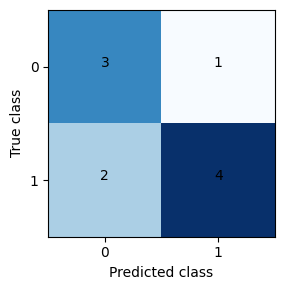

In [7]:
import torch
import matplotlib.pyplot
demo_targets = torch.tensor([0,0,0,0,1,1,1,1,1,1])
demo_preds = torch.tensor([0,0,0,1,0,0,1,1,1,1])
demo_cm = torch.zeros((2,2),dtype=torch.int64)
for demo_t,demo_p in zip(demo_targets,demo_preds):
    demo_cm[int(demo_t),int(demo_p)] += 1
demo_pacc = demo_cm.diagonal().float()/demo_cm.sum(dim=1).clamp(min=1)
demo_mis = (demo_preds != demo_targets).nonzero(as_tuple=False).squeeze(1)
print('혼동행렬:',demo_cm,'클래스별 정확도:',demo_pacc,'오분류 위치:',demo_mis,sep='\n')
assert demo_cm.tolist() == [[3,1],[2,4]]
matplotlib.pyplot.figure(figsize=(4,3))
matplotlib.pyplot.imshow(demo_cm.numpy(),cmap='Blues')
for demo_r in range(2):
    for demo_c in range(2):
        matplotlib.pyplot.text(demo_c,demo_r,str(demo_cm[demo_r,demo_c].item()),ha='center')
matplotlib.pyplot.xlabel('Predicted class'); matplotlib.pyplot.ylabel('True class')
matplotlib.pyplot.xticks([0,1]); matplotlib.pyplot.yticks([0,1])
matplotlib.pyplot.tight_layout(); matplotlib.pyplot.show()

### 잠깐 가리고 설명하기

cm[2,5]=7은 무엇을 뜻하나요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

실제 클래스2인 이미지를 클래스5로 예측한 경우가7장이라는 뜻입니다.

</details>

<a id="section-7"></a>
# 7) 추가 이해 · Activation Map 시각화 — 시험 범위 밖

**Activation은 이미지가 들어갔을 때 레이어가 계산한 출력값**입니다. hook(후크)은 그 레이어 실행 직후 출력을 받아 두는 함수입니다.

```text
이미지 (1,3,32,32) → 모델 순전파
                         │ 지정한 Conv를 지날 때
                         └→ hook(m, i, o): 출력 o 저장
                               ↓ batch축의 첫 항목 [0]
                            (C,H,W) → 큰 반응 채널 선택 → 그림
```

예: `layer2.1.conv2`는 layer2의 두 번째 블록(인덱스1)의 conv2입니다. 출력은 `(1,128,16,16)`, [0] 뒤 `(128,16,16)`. **이 위치는 BN·잔차 덧셈·최종 ReLU 이전 Conv 출력**입니다. 큰 절댓값 평균 채널을 그릴 뿐, Grad-CAM이나 클래스 기여도 계산은 아닙니다. `h.remove()`로 후크를 해제합니다.

## 원본 전체 셀 19 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 19 · L1~L10

```python
def get_module_by_name(model: nn.Module, name: str) -> nn.Module:
    cur = model  # 시작 모듈
    for part in name.split('.'):  # 점(.) 기준으로 순회
        if part.isdigit():
            cur = cur[int(part)]  # Sequential 인덱스 접근
        else:
            cur = getattr(cur, part)  # attribute 접근
    return cur

def capture_activation(model, layer_name, x_single):
```

**L1.** `get_module_by_name` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L2.** 찾기를 모델 전체에서 시작합니다. cur는 현재 탐색 중인 모듈입니다.

**L3.** 점으로 경로를 나눠 순서대로 따라갑니다. layer2.1.conv2→layer2,1,conv2.

**L4.** 경로 조각이 숫자 문자열인지 검사합니다. 1이면 Sequential의 인덱스로 접근합니다.

**L5.** 문자열 번호를 정수로 바꿔 해당 순서의 하위 모듈을 선택합니다. [1]은 두 번째입니다.

**L6.** 바로 앞 if 조건이 거짓일 때 이 분기의 들여쓴 코드를 실행합니다.

**L7.** getattr(객체, 문자열)은 그 이름의 속성을 꺼냅니다. getattr(model,"layer2")는 model.layer2와 같습니다.

**L8.** 경로를 모두 따라간 최종 레이어 객체를 반환합니다.

**L10.** `capture_activation` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

### 셀 19 · L11~L20

```python
    layer = get_module_by_name(model, layer_name)  # target layer
    activ = {}  # 저장용 dict
    def hook(m, i, o):  # callback function
        activ['feat'] = o.detach().cpu()  # (B,C,H,W) 저장

    h = layer.register_forward_hook(hook)  # target layer처리시 forward hook 등록 (hook 함수 실행)
    model.eval()  # eval 모드
    with torch.no_grad():
        _ = model(x_single)  # forward 수행
    h.remove()  # hook 제거
```

**L11.** 문자열 경로를 실제 모듈 객체로 바꿉니다. 이후 hook을 걸거나 weight를 읽을 대상입니다.

**L12.** 후크가 얻은 출력을 저장할 빈 딕셔너리를 만듭니다. 내부 hook 함수가 이 딕셔너리를 사용합니다.

**L13.** `hook` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다. m은 모듈, i는 입력 튜플, o는 출력이며 실행 직후 자동으로 전달됩니다.

**L14.** 후크의 출력 o를 gradient 연결 없이 CPU로 가져와 feat 키에 넣습니다. shape는(B,C,H,W). detach만으로 복사되지는 않으며 CPU 이동 여부에 따라 저장 공간이 달라질 수 있습니다.

**L16.** 이 레이어가 forward를 마칠 때 hook을 호출하도록 등록하고 제거용 handle을 h에 받습니다. 등록하는 줄 자체에서 hook이 실행되는 것은 아닙니다.

**L17.** 평가 모드로 바꿉니다. 기본 BN은 누적 통계, Dropout은 비활성화합니다. gradient 기록을 끄는 기능과는 별개입니다.

**L18.** 이 블록 안에서는 역전파용 그래프를 기록하지 않습니다. 그림만 볼 것이므로 메모리를 아낍니다.

**L19.** 모델 전체를 실제로 실행해야 지정 레이어의 후크도 호출됩니다. 마지막 logits는 _에 받아 사용하지 않습니다.

**L20.** 등록한 후크를 해제합니다. 다음 forward에서도 불필요하게 계속 기록되는 것을 막습니다.

### 셀 19 · L21~L30

```python
    assert 'feat' in activ, f"Hook failed for layer {layer_name}"  # 방어 코드
    return activ['feat'][0]  # (C,H,W) 반환

def show_topk_activation_grid(feat_chw, title, topk=16):
    ch_scores = feat_chw.abs().mean(dim=(1,2))  # 채널별 평균 크기 점수
    idx = torch.topk(ch_scores, k=min(topk, feat_chw.shape[0])).indices  # Top-K 채널 인덱스
    maps = []  # (K,1,H,W)로 만들 리스트
    for ci in idx:
        m = feat_chw[int(ci)]  # (H,W)
        m = (m - m.min()) / (m.max() - m.min() + 1e-6)  # 0~1 정규화
```

**L21.** feat가 저장되었는지 확인합니다. 저장되지 않았다면 AssertionError와 메시지로 후크 실패를 알립니다.

**L22.** 배치에서 첫 이미지의 특징만 꺼냅니다. (1,C,H,W)→(C,H,W)입니다.

**L24.** `show_topk_activation_grid` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L25.** 각 채널의 절댓값을 공간축 H,W=(1,2)로 평균냅니다. (C,H,W)→(C,), 큰 반응 채널 선택용 점수입니다.

**L26.** 채널 점수 상위 k개의 인덱스를 구합니다. min은 실제 채널 수보다 많은 k를 요청하지 않게 합니다.

**L27.** 뒤에서 사용할 항목을 담는 리스트를 만듭니다. 빈 리스트에는 반복문에서 append로 항목을 추가합니다.

**L28.** 리스트나 텐서에서 항목을 하나씩 꺼내 들여쓴 본문을 반복합니다. 변수 두 개면 항목의 두 값을 나누어 받습니다.

**L29.** 선택된 채널의 특징맵 하나를 꺼냅니다. (C,H,W)에서(H,W)가 됩니다.

**L30.** 그림 하나의 최솟값을0, 최댓값을 약1로 맞춥니다. 1e-6은 모든 값이 같을 때0으로 나누지 않게 합니다. 채널별 별도 정규화라 원래 채널간 크기 비교와 다릅니다.

### 셀 19 · L31~L40

```python
        maps.append(m[None, None, ...])  # (1,1,H,W)
    maps = torch.cat(maps, dim=0)  # (K,1,H,W)
    grid = torchvision.utils.make_grid(maps, nrow=8, padding=2)  # grid 생성(종종 3채널로 변환되기도 함)
    plt.figure(figsize=(12,5))
    if grid.ndim == 3 and grid.shape[0] in (3, 4):  # (3,H,W)면 HWC로 변환
        plt.imshow(grid.permute(1,2,0))
    else:  # (1,H,W)면 2D로 표시
        plt.imshow(grid.squeeze(0), cmap='viridis')
    plt.title(title)
    plt.axis('off')
```

**L31.** None 두 개로 축을 추가해 (H,W)→(1,1,H,W)를 만든 뒤 리스트에 넣습니다. ...은 나머지 모든 축입니다.

**L32.** 각(1,1,H,W)을 dim=0으로 이어(K,1,H,W)를 만듭니다. cat은 새 축을 만들지 않습니다.

**L33.** 여러 이미지를 한 장의 격자 이미지로 묶습니다. nrow=8은 한 줄에 최대 8장입니다. 출력은 CHW이며 padding 때문에 단순 32의 배수보다 커질 수 있습니다.

**L34.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L35.** 그리드가3차원이고 첫 축 채널 수가3또는4인지 검사합니다. RGB/RGBA일 때 imshow용 축 변환을 합니다.

**L36.** 채널 우선 CHW를 그림 표시용 HWC로 축 순서만 바꿉니다. 예: (3,32,32)→(32,32,3).

**L37.** 바로 앞 if 조건이 거짓일 때 이 분기의 들여쓴 코드를 실행합니다.

**L38.** 채널 축 길이가1이면 제거해(H,W)로 표시합니다. squeeze는 길이1인 축만 제거합니다.

**L39.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L40.** off이면 이미지 주변 좌표축을 감춥니다. 데이터 값은 바뀌지 않습니다.

### 셀 19 · L41~L50

```python
    plt.show()


# 1. 시각화할 레이어 이름 정의 (ResNet 구조 기준)
target_layers = {
    "Layer 1": "layer1.1.conv2", # 얕은 레이어
    "Layer 2": "layer2.1.conv2",
    "Layer 3": "layer3.1.conv2",
    "Layer 4": "layer4.1.conv2"  # 깊은 레이어
}
```

**L41.** 준비한 그림을 화면에 표시합니다.

**L44.** 실행되지 않는 주석입니다. 1. 시각화할 레이어 이름 정의 (ResNet 구조 기준)

**L45.** 화면에 보일 이름을 실제 모듈 경로와 연결하는 딕셔너리입니다. 이후 items()로 키·값 쌍을 순회합니다.

**L46.** layer별 두 번째 BasicBlock의 conv2를 선택합니다. 경로의 .1은0부터 세는 두 번째 블록이며, BN·덧셈 전 Conv 출력입니다.

**L47.** layer별 두 번째 BasicBlock의 conv2를 선택합니다. 경로의 .1은0부터 세는 두 번째 블록이며, BN·덧셈 전 Conv 출력입니다.

**L48.** layer별 두 번째 BasicBlock의 conv2를 선택합니다. 경로의 .1은0부터 세는 두 번째 블록이며, BN·덧셈 전 Conv 출력입니다.

**L49.** layer별 두 번째 BasicBlock의 conv2를 선택합니다. 경로의 .1은0부터 세는 두 번째 블록이며, BN·덧셈 전 Conv 출력입니다.

**L50.** 앞에서 시작한 리스트·함수 호출·딕셔너리를 닫습니다. 이 줄 자체에 별도 계산은 없습니다.

### 셀 19 · L51~L60

```python

# 2. 입력 이미지 선택(원하면 idx 변경)
idx = 10  # 샘플 인덱스
x, y = test_set[idx]   # 샘플 로드
x_in = x.unsqueeze(0).to(device)

img0 = denorm(x.unsqueeze(0)).squeeze(0).clamp(0,1)
plt.figure(figsize=(3,3))
plt.imshow(img0.permute(1,2,0))
plt.title(f'Input (GT={class_names[y]})')
```

**L52.** 실행되지 않는 주석입니다. 2. 입력 이미지 선택(원하면 idx 변경)

**L53.** 0부터 세는11번째 평가 샘플을 선택합니다. 클래스10을 뜻하는 것이 아닙니다.

**L54.** 지정 인덱스의 평가 이미지와 정답을 꺼냅니다. x=(3,32,32), y는 클래스 번호입니다.

**L55.** 앞에 배치 축을 추가하고 device로 옮깁니다. (3,32,32)→(1,3,32,32)입니다.

**L57.** 정규화를 역변환한 후 clamp(0,1)로 표시 범위를 제한합니다. 앞의 슬라이스나 인덱싱으로 표시할 이미지만 선택합니다. shape는 선택한 이미지 수에 맞습니다.

**L58.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L59.** 채널 우선 CHW를 그림 표시용 HWC로 축 순서만 바꿉니다. 예: (3,32,32)→(32,32,3).

**L60.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

### 셀 19 · L61~L70

```python
plt.axis('off')
plt.show()

# 3. 반복문을 통해 각 레이어의 Activation 추출 및 시각화
print(f"{'Layer Name':<20} | {'Activation Shape'}")
print("-" * 45)

for title, layer_name in target_layers.items():
    # Activation 캡처
    feat = capture_activation(model, layer_name, x_in)
```

**L61.** off이면 이미지 주변 좌표축을 감춥니다. 데이터 값은 바뀌지 않습니다.

**L62.** 준비한 그림을 화면에 표시합니다.

**L64.** 실행되지 않는 주석입니다. 3. 반복문을 통해 각 레이어의 Activation 추출 및 시각화

**L65.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L66.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L68.** 딕셔너리의 키·값 쌍을 순서대로 꺼냅니다. 화면 제목과 실제 레이어 경로를 함께 받습니다.

**L69.** 실행되지 않는 주석입니다. Activation 캡처

**L70.** 모델 순전파 중 지정한 레이어 출력을 잡아 첫 이미지의(C,H,W) 특징을 받습니다.

### 셀 19 · L71~L76

```python

    # 정보 출력
    print(f"{layer_name:<20} | {tuple(feat.shape)}") # (C,H,W)

    # 시각화 (Top-16 채널)
    show_topk_activation_grid(feat, f'Activation maps (Top-16) @ {title} ({layer_name})', topk=16)
```

**L72.** 실행되지 않는 주석입니다. 정보 출력

**L73.** 괄호 안의 값이나 메시지를 화면에 출력합니다. f-string의 중괄호는 변수 값을 넣고, 
은 줄바꿈입니다. 출력만으로 모델 가중치가 바뀌지는 않습니다.

**L75.** 실행되지 않는 주석입니다. 시각화 (Top-16 채널)

**L76.** 반응이 큰 최대16채널을 골라 그리드로 표시합니다. 채널 평균 절댓값 기준이며 클래스별 기여도는 아닙니다.

## 7번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

Conv 출력: (1, 128, 16, 16) 한 장: (128, 16, 16)


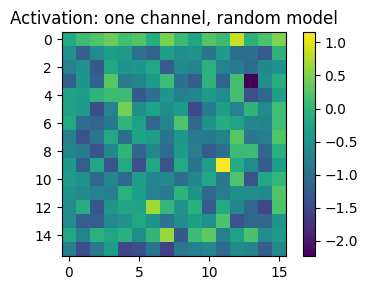

In [8]:
import torch
import matplotlib.pyplot
# 2번 작은 실험에서 만든 demo_resnet을 사용합니다. 임의 초기화 모델입니다.
demo_activation = {}
def demo_hook(module,inputs,output):
    demo_activation['feat'] = output.detach().cpu().clone()
demo_handle = demo_resnet.layer2[1].conv2.register_forward_hook(demo_hook)
try:
    demo_resnet.eval()
    with torch.no_grad():
        demo_resnet(demo_input)
finally:
    demo_handle.remove()
demo_feat = demo_activation['feat'][0]
print('Conv 출력:',tuple(demo_activation['feat'].shape),'한 장:',tuple(demo_feat.shape))
assert demo_feat.shape == (128,16,16)
matplotlib.pyplot.figure(figsize=(4,3))
matplotlib.pyplot.imshow(demo_feat[0].numpy(),cmap='viridis')
matplotlib.pyplot.title('Activation: one channel, random model')
matplotlib.pyplot.colorbar(); matplotlib.pyplot.tight_layout(); matplotlib.pyplot.show()

### 잠깐 가리고 설명하기 · 추가 이해용

입력 이미지를 바꾸면 activation도 바뀔 수 있나요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

네. activation은 현재 입력을 레이어로 계산한 결과입니다. 이 질문은 추가 이해용이며 시험 문제는 아닙니다.

</details>

<a id="section-8"></a>
# 8) 추가 이해 · Convolution Kernel — 시험 범위 밖

**Kernel 그림은 입력 이미지에 대한 출력이 아니라, 학습된 필터 가중치 자체**입니다.

```text
첫 Conv weight: (64,3,3,3) = (출력채널, 입력채널, 커널높이, 커널너비)
  → w[0]: (3,3,3) → RGB 3×3 필터 하나

layer2.0.conv1 weight: (128,64,3,3)
  → w[0]: (64,3,3) → 입력채널 평균 → (1,3,3)
```

예: 64개 입력채널을 평균낸 그림은 3×3 회색 그림 하나입니다. 이 평균 그림만으로 모든 채널의 필터 정보를 볼 수는 없습니다. 이미지에 따라 달라지는 Activation Map과, 입력 없이도 꺼낼 수 있는 weight를 구분하세요. 그림 표시용 min-max 정규화는 학습 가중치를 다시 학습시키는 과정이 아닙니다.

## 원본 전체 셀 21 · 코드와 줄별 설명

아래 코드는 원문 그대로입니다. 줄 번호는 **원본 셀 안의 번호**입니다. 빈 줄은 설명을 생략하며, 주석의 부정확한 표현은 실행 줄 해설에서 바로잡습니다. 긴 코드는 최대 10줄씩 나누었습니다.

### 셀 21 · L1~L10

```python
def show_conv_kernels(model, layer_name='conv1', max_kernels=64):
    layer = get_module_by_name(model, layer_name)  # target layer
    assert isinstance(layer, nn.Conv2d)  # conv인지 확인
    w = layer.weight.detach().cpu()  # (O,I,kH,kW)
    O, I, kH, kW = w.shape  # shape 분해
    K = min(O, max_kernels)  # 시각화할 커널 수 제한

    imgs = []  # 커널 이미지 리스트
    for o in range(K):
        ker = w[o]  # (I,kH,kW)
```

**L1.** `show_conv_kernels` 함수를 정의합니다. 괄호 안은 전달받을 값이며 들여쓴 본문은 호출할 때 실행합니다. `=값`은 기본값, `: int`·`->`는 타입 힌트입니다.

**L2.** 문자열 경로를 실제 모듈 객체로 바꿉니다. 이후 hook을 걸거나 weight를 읽을 대상입니다.

**L3.** 대상이 torch.nn.Conv2d 인스턴스인지 확인합니다. 다른 종류면 AssertionError로 중단합니다.

**L4.** 학습된 필터 weight를 gradient 연결 없이 CPU로 가져옵니다. (출력채널O,입력채널I,kH,kW)이며 이미지 배치 shape가 아닙니다.

**L5.** weight shape의 네 숫자를 변수 네 개에 나누어 담습니다. 첫 Conv는64,3,3,3입니다.

**L6.** 실제 출력 필터 수와 요청한 최대 개수 중 작은 수만 표시합니다.

**L8.** 뒤에서 사용할 항목을 담는 리스트를 만듭니다. 빈 리스트에는 반복문에서 append로 항목을 추가합니다.

**L9.** range의 시작은 포함하고 끝은 제외하여 반복합니다. range(1,횟수+1)은1부터횟수까지, range(K)는0부터K-1까지입니다.

**L10.** o번째 출력 필터를 꺼냅니다. (O,I,kH,kW)→(I,kH,kW). 출력 하나를 만드는 데 입력 채널 전체를 사용합니다.

### 셀 21 · L11~L20

```python
        if I == 3:  # RGB 입력이면 그대로 시각화 가능
            img = (ker - ker.min()) / (ker.max() - ker.min() + 1e-6)  # 0~1 정규화
            imgs.append(img)  # (3,kH,kW)
        else:  # 입력 채널이 많으면 평균내서 2D로 시각화
            img2d = ker.mean(dim=0, keepdim=True)  # (1,kH,kW)
            img2d = (img2d - img2d.min()) / (img2d.max() - img2d.min() + 1e-6)  # 정규화
            imgs.append(img2d)  # (1,kH,kW)

    imgs = torch.stack(imgs, dim=0)  # (K,C,kH,kW)
    grid = torchvision.utils.make_grid(imgs, nrow=8, padding=2)  # grid 생성
```

**L11.** 입력채널이 RGB3이면 필터를3채널 작은 색상 이미지처럼 표시할 수 있습니다.

**L12.** 필터 전체의 min/max로 표시용0~1 값을 만듭니다. 새 결과 텐서이며 원본 weight를 직접 바꾸지 않습니다.

**L13.** RGB 필터 이미지(3,kH,kW)를 리스트에 추가합니다.

**L14.** 바로 앞 if 조건이 거짓일 때 이 분기의 들여쓴 코드를 실행합니다.

**L15.** 입력채널 축0으로 평균냅니다. keepdim=True라(I,kH,kW)→(1,kH,kW). 여러 채널 정보가 평균으로 축약됩니다.

**L16.** 평균낸 회색 필터의 값을 표시용0~1로 바꿉니다. 1e-6은0나누기 방지입니다.

**L17.** 단일채널 필터 이미지(1,kH,kW)를 리스트에 넣습니다.

**L19.** 같은 shape의 필터 이미지들을 새0번 축으로 묶습니다. K개의(C,kH,kW)→(K,C,kH,kW)입니다.

**L20.** 여러 이미지를 한 장의 격자 이미지로 묶습니다. nrow=8은 한 줄에 최대 8장입니다. 출력은 CHW이며 padding 때문에 단순 32의 배수보다 커질 수 있습니다.

### 셀 21 · L21~L30

```python
    plt.figure(figsize=(12,6))
    if grid.ndim == 3 and grid.shape[0] in (3,4):  # CHW면 HWC로 표시
        plt.imshow(grid.permute(1,2,0))
    else:  # 1채널이면 grayscale
        plt.imshow(grid.squeeze(0), cmap='gray')
    plt.title(f'Conv kernels @ {layer_name} | weight shape={tuple(w.shape)}')
    plt.axis('off')
    plt.show()

show_conv_kernels(model, 'conv1', max_kernels=64)  # 첫 레이어 커널
```

**L21.** 새 그림 영역을 만듭니다. figsize는 가로·세로 길이(인치)이며 텐서 shape가 아닙니다.

**L22.** 그리드가3차원이고 첫 축 채널 수가3또는4인지 검사합니다. RGB/RGBA일 때 imshow용 축 변환을 합니다.

**L23.** 채널 우선 CHW를 그림 표시용 HWC로 축 순서만 바꿉니다. 예: (3,32,32)→(32,32,3).

**L24.** 바로 앞 if 조건이 거짓일 때 이 분기의 들여쓴 코드를 실행합니다.

**L25.** 채널 축 길이가1이면 제거해(H,W)로 표시합니다. squeeze는 길이1인 축만 제거합니다.

**L26.** 그림 제목을 설정합니다. f-string이면 변수 값도 제목에 넣습니다.

**L27.** off이면 이미지 주변 좌표축을 감춥니다. 데이터 값은 바뀌지 않습니다.

**L28.** 준비한 그림을 화면에 표시합니다.

**L30.** 함수를 호출해 지정 레이어의 필터를 표시합니다. conv1=(64,3,3,3), layer2.0.conv1=(128,64,3,3)이며 후자는 입력채널을 평균내 표시합니다.

### 셀 21 · L31~L31

```python
show_conv_kernels(model, 'layer2.0.conv1', max_kernels=64)  # 중간 레이어 커널(평균 시각화)
```

**L31.** 함수를 호출해 지정 레이어의 필터를 표시합니다. conv1=(64,3,3,3), layer2.0.conv1=(128,64,3,3)이며 후자는 입력채널을 평균내 표시합니다.

## 8번 작은 실행 실험

원본 학습을 실행하는 셀이 아니라, 핵심을 확인하는 **보충 예제**입니다. 출력의 숫자·shape가 왜 나오는지 설명해 보세요.

첫 Conv weight: (64, 3, 3, 3) 필터 하나: (3, 3, 3)
중간 Conv weight: (128, 64, 3, 3) 평균 그림: (1, 3, 3)


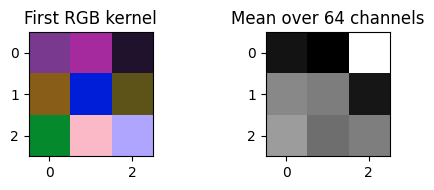

In [9]:
import torch
import matplotlib.pyplot
# 입력 없이도 weight를 읽을 수 있습니다. 이것은 activation이 아닙니다.
demo_w = demo_resnet.conv1.weight.detach().cpu()
demo_filter = demo_w[0]
demo_rgb = (demo_filter-demo_filter.min())/(demo_filter.max()-demo_filter.min()+1e-6)
print('첫 Conv weight:',tuple(demo_w.shape),'필터 하나:',tuple(demo_filter.shape))
demo_mid = demo_resnet.layer2[0].conv1.weight.detach().cpu()
demo_gray = demo_mid[0].mean(dim=0,keepdim=True)
print('중간 Conv weight:',tuple(demo_mid.shape),'평균 그림:',tuple(demo_gray.shape))
assert demo_w.shape == (64,3,3,3)
assert demo_mid.shape == (128,64,3,3)
matplotlib.pyplot.figure(figsize=(5,2))
matplotlib.pyplot.subplot(1,2,1); matplotlib.pyplot.imshow(demo_rgb.permute(1,2,0).numpy()); matplotlib.pyplot.title('First RGB kernel')
matplotlib.pyplot.subplot(1,2,2); matplotlib.pyplot.imshow(demo_gray[0].numpy(),cmap='gray'); matplotlib.pyplot.title('Mean over 64 channels')
matplotlib.pyplot.tight_layout(); matplotlib.pyplot.show()

### 잠깐 가리고 설명하기 · 추가 이해용

첫 Conv의 weight (64,3,3,3)에서 첫64는 배치 크기인가요?

**내 설명:** 여기를 더블클릭해서 적어 보세요.

<details><summary>말로 답한 뒤 비교하기</summary>

아니요. 출력 필터 개수, 즉 출력채널 수입니다. 이 질문은 추가 이해용입니다.

</details>

# 마지막 연결·복습

```text
Dataset → DataLoader → model(images) → logits → criterion + labels → loss
                                    ↑                           │
                                    └─ optimizer ← gradient ← backward
```

**다음에 직접 설명할 세 가지:** (1) F(x)+x의 두 shape가 같아야 하는 이유 (2) zero_grad와 step의 차이 (3) logits·labels·loss의 shape.

답을 채팅에 보내면 설명의 정확성을 확인합니다. 이 문서를 읽거나 예제를 실행한 것만으로 독립 구현 숙달로 기록하지 않습니다. 다음 학습일, 3수업일 뒤, 7수업일 뒤에 위 세 가지를 자료 없이 떠올려 보세요.

## 복습 자료·근거

- [기존 ResNet 9단계 그림과 코드 문제](../../lessons/0028-day03-resnet18-shape-journey.html)
- [코드 연결 복습표](../../reference/day04-resnet-code-map.html)
- [Day 4 필기](../../class-notes/day-04.md)
- [torchvision 0.20 ResNet 구현](https://docs.pytorch.org/vision/0.20/_modules/torchvision/models/resnet.html): 실제 잔차 블록·pooling·FC 흐름.
- [PyTorch AMP 예제](https://docs.pytorch.org/docs/stable/notes/amp_examples.html): scaler.scale·step·update의 구분.
- [Optimizer.zero_grad](https://docs.pytorch.org/docs/stable/generated/torch.optim.Optimizer.zero_grad.html): gradient 초기화.
- 원본 코드의 설치·다운로드·전체 CIFAR 학습은 이 안내서의 실행 검증 대상이 아닙니다. 작은 실험은 CPU 합성 데이터로 기능·shape를 확인합니다. 실제 CUDA AMP 성능과 CIFAR 정확도를 확인했다는 뜻은 아닙니다.